In [8]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterstats import zonal_stats

# ============================================================
# PATHS
# ============================================================

basin_shp = (
    "/scratch/data/CAMELS_FORCING/"
    "basin_dataset_public_v1p2/shapefiles/CAMELS_671_basins.shp"
)

recharge_dir = "/home/s0shar47/scratch/Recharge_reitz/Total_Recharge"

output_file = "/home/s0shar47/scratch/Recharge_reitz/recharge_671_gages_2000_2013.csv"

# ============================================================
# READ BASINS
# ============================================================

basins = gpd.read_file(basin_shp)

print("Number of basins:", len(basins))
print("Columns:")
print(basins.columns.tolist())

# Make sure GAGEID is available
basins["GAGEID"] = basins["GAGEID"].astype(str)

# ============================================================
# LOOP THROUGH YEARS
# ============================================================

results = []

for year in range(2000, 2014):

    tif_file = os.path.join(
        recharge_dir,
        str(year),
        f"RC_{year}.tif"
    )

    print(f"Processing {year}: {tif_file}")

    if not os.path.exists(tif_file):
        print(f"  WARNING: file not found")
        continue

    # --------------------------------------------------------
    # Open recharge raster
    # --------------------------------------------------------

    with rasterio.open(tif_file) as src:

        print("  Raster CRS:", src.crs)
        print("  Basin CRS:", basins.crs)

        # Reproject basins if necessary
        if basins.crs != src.crs:
            basins_year = basins.to_crs(src.crs)
        else:
            basins_year = basins

        # ----------------------------------------------------
        # Calculate spatial mean recharge for each basin
        # ----------------------------------------------------

        stats = zonal_stats(
            basins_year.geometry,
            tif_file,
            stats=["mean"],
            nodata=src.nodata,
            all_touched=False
        )

    # --------------------------------------------------------
    # Store results
    # --------------------------------------------------------

    year_result = pd.DataFrame({
        "GAGEID": basins["GAGEID"].values,
        "Year": year,
        "Total_Recharge_mean": [s["mean"] for s in stats]
    })

    results.append(year_result)

# ============================================================
# COMBINE ALL YEARS
# ============================================================

recharge_df = pd.concat(
    results,
    ignore_index=True
)

# ============================================================
# SAVE
# ============================================================

# recharge_df.to_csv(
#     output_file,
#     index=False
# )

print("\nFinished!")
print("Output shape:", recharge_df.shape)
display(recharge_df)

Number of basins: 671
Columns:
['GAGEID', 'Dissolve', 'POI_ID', 'PROD_UNIT', 'hru_id_pro', 'hru_id_reg', 'hru_id_loc', 'hru_id', 'hru_x', 'hru_y', 'hru_area', 'hru_elev', 'hru_slope', 'hru_aspect', 'asp_sin', 'asp_cos', 'jh_coef_hr', 'tmin_adj', 'tmax_adj', 'snarea_thr', 'hru_deplcr', 'soil_moist', 'soil_rechr', 'soil_type', 'cov_type', 'VALUE_0', 'VALUE_1', 'VALUE_2', 'VALUE_3', 'covden_sum', 'leaf_loss', 'covden_win', 'rad_trncf', 'srain_intc', 'wrain_intc', 'snow_intcp', 'hru_percen', 'soil2gw_ma', 'ssr2gw_rat', 'fastcoef_l', 'slowcoef_l', 'gwflow_coe', 'dprst_seep', 'dprst_se_1', 'dprst_flow', 'r_k_perm_w', 'r_junk', 'hru_long', 'hru_lat', 'dprst_area', 'sro_to_dpr', 'hru_segmen', 'Shape_Leng', 'Shape_Area', 'geometry']
Processing 2000: /home/s0shar47/scratch/Recharge_reitz/Total_Recharge/2000/RC_2000.tif
  Raster CRS: EPSG:4269
  Basin CRS: EPSG:5070
Processing 2001: /home/s0shar47/scratch/Recharge_reitz/Total_Recharge/2001/RC_2001.tif
  Raster CRS: EPSG:4269
  Basin CRS: EPSG:507

,GAGEID,Year,Total_Recharge_mean
0,1013500,2000,0.408170
1,1022500,2000,0.396791
2,1030500,2000,0.353920
3,1031500,2000,0.537459
4,1047000,2000,0.575586
...,...,...,...
9389,14309500,2013,0.140234
9390,14316700,2013,0.350020
9391,14325000,2013,0.384872
9392,14362250,2013,0.018121


In [ ]:
recharge_matrix = recharge_df.pivot(
    index="GAGEID",
    columns="Year",
    values="Total_Recharge_mean"
)

# recharge_matrix.to_csv(
#     "/home/s0shar47/scratch/Recharge_reitz/Total_recharge_671_gages_2000_2013_wide.csv"
# )

recharge_matrix

Year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
GAGEID,,,,,,,,,,,,,,
10023000,0.148516,0.114298,0.119531,0.139353,0.189855,0.235197,0.205456,0.100710,0.172817,0.195234,0.279061,0.284379,0.125364,0.112306
1013500,0.408170,0.184020,0.298984,0.476105,0.389792,0.656723,0.468685,0.436017,0.550037,0.431003,0.425820,0.573497,0.388041,0.414531
10166430,0.055725,0.040562,0.028663,0.043847,0.070288,0.091653,0.074565,0.039667,0.049504,0.069996,0.105836,0.092655,0.043103,0.061236
10172700,0.101100,0.062073,0.040099,0.081129,0.118062,0.144216,0.107472,0.062146,0.086217,0.087311,0.165961,0.120952,0.069828,0.062428
10172800,0.194855,0.154628,0.109114,0.180815,0.271115,0.290834,0.306695,0.148894,0.202273,0.264251,0.356297,0.283783,0.157330,0.198099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9505800,0.028932,0.031383,0.017225,0.033234,0.064157,0.056316,0.019739,0.033261,0.065964,0.019330,0.125245,0.029944,0.025819,0.050532
9508300,0.034012,0.037471,0.016262,0.042673,0.051248,0.054567,0.019078,0.027657,0.059040,0.020898,0.113763,0.031079,0.025276,0.068553
9510200,0.052426,0.054940,0.014972,0.062193,0.068637,0.066455,0.019548,0.045803,0.073217,0.023196,0.093948,0.031469,0.034480,0.048747


In [2]:
import numpy as np
import os
import pandas as pd


# ============================================================
# SETTINGS
# ============================================================

objectives = ["Single", "Multi"]

methods = [
    # "USGS",
    "Furey",
    "Eckhardt",
    "LocalHYSEP"
]

START_YEAR = 2000
END_YEAR = 2013

YEARS = np.arange(
    START_YEAR,
    END_YEAR + 1
)

test = "PUR"

models = [
    "HBV",
    "HBV_capillary",
    "marrmot_PRMS"
]


# ============================================================
# DATES
# ============================================================

dates = pd.date_range(
    "1981-01-01",
    "2014-12-31",
    freq="D"
)


# ============================================================
# OUTPUT DIRECTORY
# ============================================================

OUTPUT_DIR = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/Total_Recharge_Basin_wise_csv_NSE_loss"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


# ============================================================
# TIFF BASIN RECHARGE
# ============================================================

TIFF_CSV = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/Total_recharge_671_gages_2000_2013_wide.csv"
)

tiff_data = pd.read_csv(
    TIFF_CSV
)


# ============================================================
# FIND GAGEID COLUMN
# ============================================================

if "GAGEID" in tiff_data.columns:

    ID_COL = "GAGEID"

elif "STAID" in tiff_data.columns:

    ID_COL = "STAID"

elif "ID" in tiff_data.columns:

    ID_COL = "ID"

else:

    raise ValueError(
        "No GAGEID/STAID/ID column found."
    )


# ============================================================
# FORCE GAGEIDS TO INTEGER
# ============================================================

tiff_data["GAGEID_INT"] = pd.to_numeric(
    tiff_data[ID_COL],
    errors="coerce"
)

tiff_data = tiff_data[
    tiff_data["GAGEID_INT"].notna()
].copy()

tiff_data["GAGEID_INT"] = (
    tiff_data["GAGEID_INT"]
    .astype(np.int64)
)


# ============================================================
# CHECK DUPLICATE GAGEIDS
# ============================================================

if tiff_data["GAGEID_INT"].duplicated().any():

    duplicate_ids = (
        tiff_data.loc[
            tiff_data["GAGEID_INT"].duplicated(
                keep=False
            ),
            "GAGEID_INT"
        ]
        .unique()
    )

    raise ValueError(
        f"Duplicate GAGEIDs in TIFF CSV: "
        f"{duplicate_ids}"
    )


# ============================================================
# CREATE TIFF LOOKUP
# ============================================================

# GAGEID -> [2000, 2001, ..., 2013]

tiff_lookup = {}

for _, row in tiff_data.iterrows():

    gauge = int(
        row["GAGEID_INT"]
    )

    tiff_lookup[gauge] = np.array(
        [
            row[f"{year}"]
            for year in YEARS
        ],
        dtype=float
    )


print(
    f"TIFF basins: {len(tiff_lookup)}"
)


# ============================================================
# FUNCTION: GET DYNAMIC PARAMETERS
# ============================================================

def get_dyn(model):

    if model == "HBV":

        return (
            "parBETA_parBETAET_"
        )

    elif model == "HBV_capillary":

        return (
            "parBETA_parBETAET_"
            "parK0_parUZL_"
        )

    elif model == "marrmot_PRMS":

        return (
            "alpha_cgw_scx_tt_"
        )

    else:

        raise ValueError(
            f"Unknown model: {model}"
        )


# ============================================================
# FUNCTION: CALCULATE ANNUAL SUMS OR MEANS
# ============================================================
def annual_sums(recharge):

    recharge = np.asarray(
        recharge,
        dtype=float
    )

    # --------------------------------------------------------
    # Expected input:
    #
    # Either:
    #     (time, basins)
    #
    # or:
    #     (basins, time)
    # --------------------------------------------------------

    if recharge.ndim != 2:

        raise ValueError(
            f"Expected 2D recharge array, "
            f"got shape {recharge.shape}"
        )

    # --------------------------------------------------------
    # If input is:
    #
    # (time, basins)
    #
    # transpose it to:
    #
    # (basins, time)
    # --------------------------------------------------------

    if recharge.shape[0] == len(dates):

        recharge = recharge.T

    # --------------------------------------------------------
    # Otherwise make sure second dimension is time
    # --------------------------------------------------------

    elif recharge.shape[1] != len(dates):

        raise ValueError(
            f"Unexpected recharge shape: "
            f"{recharge.shape}. "
            f"Expected one dimension to equal "
            f"{len(dates)}."
        )

    # --------------------------------------------------------
    # Create output array
    #
    # rows    = basins
    # columns = years
    # --------------------------------------------------------

    annual = np.full(
        (
            recharge.shape[0],
            len(YEARS)
        ),
        np.nan
    )

    # --------------------------------------------------------
    # Calculate annual sums
    # --------------------------------------------------------

    for j, year in enumerate(YEARS):

        mask = (
            dates.year == year
        )

        annual[:, j] = np.nansum(
            recharge[:, mask],
            axis=1
        )

    # --------------------------------------------------------
    # Convert from mm to m
    #
    # Assuming recharge is originally in mm/day.
    # --------------------------------------------------------

    annual = annual / 1000.0

    return annual


##########################################################################################################
##########################################################################################################

def annual_means(recharge):

    recharge = np.asarray(
        recharge,
        dtype=float
    )


    # --------------------------------------------------------
    # Expected input:
    #
    # Either:
    #     (time, basins)
    #
    # or:
    #     (basins, time)
    # --------------------------------------------------------

    if recharge.ndim != 2:

        raise ValueError(
            f"Expected 2D recharge array, "
            f"got shape {recharge.shape}"
        )


    # --------------------------------------------------------
    # If input is:
    #
    # (time, basins)
    #
    # transpose it to:
    #
    # (basins, time)
    # --------------------------------------------------------

    if recharge.shape[0] == len(dates):

        recharge = recharge.T


    # --------------------------------------------------------
    # Otherwise make sure second dimension is time
    # --------------------------------------------------------

    elif recharge.shape[1] != len(dates):

        raise ValueError(
            f"Unexpected recharge shape: "
            f"{recharge.shape}. "
            f"Expected one dimension to equal "
            f"{len(dates)}."
        )


    # --------------------------------------------------------
    # Create output array
    #
    # rows    = basins
    # columns = years
    # --------------------------------------------------------

    annual = np.full(
        (
            recharge.shape[0],
            len(YEARS)
        ),
        np.nan
    )


    # --------------------------------------------------------
    # Calculate annual means
    # --------------------------------------------------------

    for j, year in enumerate(YEARS):

        mask = (
            dates.year == year
        )

        annual[:, j] = np.nansum(
            recharge[:, mask],
            axis=1
        )


    return annual


# ============================================================
# FUNCTION: LOAD RECHARGE / PERCOLATION DATA
# ============================================================

def load_recharge(
    model,
    folder,
    run_name,
    dyn
):

    base_path = os.path.join(
        folder,
        run_name,
        dyn,
        "ts1980_2014"
    )


    # ========================================================
    # HBV
    #
    # Recharge = percolation
    # ========================================================

    if model == "HBV":

        percolation_path = os.path.join(
            base_path,
            "percolation.npy"
        )

        if not os.path.exists(
            percolation_path
        ):

            print(
                "Missing percolation.npy:"
            )

            print(
                percolation_path
            )

            return None


        print(
            "Loading percolation.npy"
        )

        percolation = np.squeeze(
            np.load(
                percolation_path
            )
        )

        return percolation


    # ========================================================
    # HBV_capillary
    #
    # Recharge =
    #
    # percolation - capillary
    # ========================================================

    elif model == "HBV_capillary":

        percolation_path = os.path.join(
            base_path,
            "percolation.npy"
        )

        capillary_path = os.path.join(
            base_path,
            "capillary.npy"
        )


        if not os.path.exists(
            percolation_path
        ):

            print(
                "Missing percolation.npy:"
            )

            print(
                percolation_path
            )

            return None


        if not os.path.exists(
            capillary_path
        ):

            print(
                "Missing capillary.npy:"
            )

            print(
                capillary_path
            )

            return None


        print(
            "Loading percolation.npy"
        )

        percolation = np.squeeze(
            np.load(
                percolation_path
            )
        )


        print(
            "Loading capillary.npy"
        )

        capillary = np.squeeze(
            np.load(
                capillary_path
            )
        )


        # ----------------------------------------------------
        # Check shapes
        # ----------------------------------------------------

        if percolation.shape != capillary.shape:

            raise ValueError(
                "percolation and capillary "
                "have different shapes: "
                f"{percolation.shape} vs "
                f"{capillary.shape}"
            )


        # ----------------------------------------------------
        # Calculate recharge
        # ----------------------------------------------------

        recharge = (
            percolation
            -
            capillary
        )


        return recharge


    # ========================================================
    # marrmot_PRMS
    #
    # Recharge =
    #
    # flux_gad + flux_sep
    # ========================================================

    elif model == "marrmot_PRMS":

        flux_gad_path = os.path.join(
            base_path,
            "flux_gad.npy"
        )

        flux_sep_path = os.path.join(
            base_path,
            "flux_sep.npy"
        )


        if not os.path.exists(
            flux_gad_path
        ):

            print(
                "Missing flux_gad.npy:"
            )

            print(
                flux_gad_path
            )

            return None


        if not os.path.exists(
            flux_sep_path
        ):

            print(
                "Missing flux_sep.npy:"
            )

            print(
                flux_sep_path
            )

            return None


        print(
            "Loading flux_gad.npy"
        )

        flux_gad = np.squeeze(
            np.load(
                flux_gad_path
            )
        )


        print(
            "Loading flux_sep.npy"
        )

        flux_sep = np.squeeze(
            np.load(
                flux_sep_path
            )
        )


        # ----------------------------------------------------
        # Check shapes
        # ----------------------------------------------------

        if flux_gad.shape != flux_sep.shape:

            raise ValueError(
                "flux_gad and flux_sep "
                "have different shapes: "
                f"{flux_gad.shape} vs "
                f"{flux_sep.shape}"
            )


        # ----------------------------------------------------
        # Calculate recharge
        # ----------------------------------------------------

        recharge = (
            flux_gad
            +
            flux_sep
        )


        return recharge


    else:

        raise ValueError(
            f"Unknown model: {model}"
        )


# ============================================================
# NUMBER OF REGIONS
# ============================================================

if test == "PUB":

    n_regions = 11

else:

    n_regions = 8


# ============================================================
# LOOP METHODS
# ============================================================

for method in methods:


    # ========================================================
    # LOOP MODELS
    # ========================================================

    for model in models:


        print("\n")
        print("=" * 80)

        print(
            f"METHOD = {method}"
        )

        print(
            f"MODEL  = {model}"
        )

        print(
            f"TEST   = {test}"
        )

        print("=" * 80)


        # ====================================================
        # GET DYNAMIC PARAMETER NAME
        # ====================================================

        dyn = get_dyn(
            model
        )


        # ====================================================
        # HOLD ALL GAGES FROM ALL REGIONS
        # ====================================================

        all_annual_results = []


        # ====================================================
        # LOOP REGIONS
        # ====================================================

        for region in range(
            1,
            n_regions + 1
        ):


            print(
                f"\nRegion {region}"
            )


            # =================================================
            # PATHS
            # =================================================

            if test == "PUB":

                folder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUB/"
                    f"{method}_{objectives[1]}/"
                    f"{region}/"
                )

                sfolder = (
                    f"/home/s0shar47/scratch/"
                    f"OUTPUTS_Paper1/PUB/"
                    f"OUTPUTS_PUB_{objectives[0]}/"
                    f"{region}/"
                )

                forcing_path = (
                    f"/scratch/data/"
                    f"PUB_DATA/test/{region}/"
                    f"daymet_19800101_20141231_"
                    f"forcing_671_baseflow_mmday.npy"
                )


            else:

                # folder = (
                #     f"/home/s0shar47/scratch/"
                #     f"OUTPUTS_Paper1/PUR/"
                #     f"{method}_{objectives[1]}/"
                #     f"Region_{region}/"
                # )

                folder= (f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/{method}_Multi/NSE/{model}/Region_{region}/")

                sfolder= (f"/home/s0shar47/scratch/OUTPUTS_Paper1v2/PUR/Single/NSE/{model}/Region_{region}/")

                # sfolder = (
                #     f"/home/s0shar47/scratch/"
                #     f"OUTPUTS_Paper1/PUR/"
                #     f"OUTPUTS_PUR_{objectives[0]}/"
                #     f"Region_{region}/"
                # )

                forcing_path = (
                    f"/scratch/data/"
                    f"PUR_DATA/test/Region_{region}/"
                    f"daymet_19800101_20141231_"
                    f"forcing_671_baseflow_mmday.npy"
                )


            # =================================================
            # RUN NAME
            # =================================================

            run_name = (
                f"LSTM_{model}_"
                f"E50_R365_B100_H256_"
                f"tr1989_1999_n16_111111"
            )


            # =================================================
            # CHECK FORCING
            # =================================================

            if not os.path.exists(
                forcing_path
            ):

                print(
                    "Missing forcing file -- skipping region"
                )

                print(
                    forcing_path
                )

                continue


            # =================================================
            # LOAD FORCING
            # =================================================

            print(
                "Loading forcing..."
            )

            forcing = np.load(
                forcing_path
            )


            # =================================================
            # LOAD OLD RECHARGE
            #
            # Uses Single objective directory
            # =================================================

            print(
                "\nLoading OLD recharge..."
            )

            old_recharge = load_recharge(
                model=model,
                folder=sfolder,
                run_name=run_name,
                dyn=dyn
            )


            if old_recharge is None:

                print(
                    "Could not load OLD recharge "
                    "-- skipping region"
                )

                continue


            # =================================================
            # LOAD NEW RECHARGE
            #
            # Uses Multi objective directory
            # =================================================

            print(
                "\nLoading NEW recharge..."
            )

            new_recharge = load_recharge(
                model=model,
                folder=folder,
                run_name=run_name,
                dyn=dyn
            )


            if new_recharge is None:

                print(
                    "Could not load NEW recharge "
                    "-- skipping region"
                )

                continue


            # =================================================
            # CHECK OLD / NEW SHAPES
            # =================================================

            if old_recharge.shape != new_recharge.shape:

                raise ValueError(
                    "OLD and NEW recharge arrays "
                    "have different shapes: "
                    f"{old_recharge.shape} vs "
                    f"{new_recharge.shape}"
                )


            # =================================================
            # CALCULATE ANNUAL MEANS
            #
            # This happens AFTER constructing recharge:
            #
            # HBV:
            #     percolation
            #
            # HBV_capillary:
            #     percolation - capillary
            #
            # marrmot:
            #     flux_gad + flux_sep
            # =================================================

            print(
                "\nCalculating annual means..."
            )

            annual_old = annual_sums(
                old_recharge
            )

            annual_new = annual_sums(
                new_recharge
            )


            # =================================================
            # NUMBER OF BASINS
            # =================================================

            n_basins = (
                annual_old.shape[0]
            )

            print(
                f"Basins: {n_basins}"
            )


            # =================================================
            # LOOP BASINS
            # =================================================

            for basin in range(
                n_basins
            ):


                # =================================================
                # GET GAGEID
                #
                # GAGEID = forcing[basin, 0, 14]
                # =================================================

                gauge_raw = forcing[
                    basin,
                    0,
                    14
                ]


                # =================================================
                # CHECK GAGEID
                # =================================================

                if not np.isfinite(
                    gauge_raw
                ):

                    continue


                gauge = int(
                    gauge_raw
                )


                # =================================================
                # CHECK TIFF MATCH
                # =================================================

                if gauge not in tiff_lookup:

                    print(
                        f"  GAGEID {gauge} "
                        f"not found in TIFF CSV"
                    )

                    continue


                # =================================================
                # GET TIFF ANNUAL VALUES
                # =================================================

                tiff_series = tiff_lookup[
                    gauge
                ]


                # =================================================
                # GET SIMULATION ANNUAL VALUES
                # =================================================

                old_series = annual_old[
                    basin
                ]

                new_series = annual_new[
                    basin
                ]


                # =================================================
                # ADD ONE ROW FOR EACH YEAR
                # =================================================

                for j, year in enumerate(
                    YEARS
                ):

                    all_annual_results.append(
                        {
                            "year": int(year),

                            "gageid": int(gauge),

                            "tiff": tiff_series[j],

                            "sim_old": old_series[j],

                            "sim_new": new_series[j]
                        }
                    )


                print(
                    f"  GAGEID {gauge}: "
                    f"2000-2013 added"
                )


        # ========================================================
        # SAVE CSV FOR THIS METHOD + MODEL
        # ========================================================

        if len(
            all_annual_results
        ) > 0:


            annual_df = pd.DataFrame(
                all_annual_results,
                columns=[
                    "year",
                    "gageid",
                    "tiff",
                    "sim_old",
                    "sim_new"
                ]
            )


            # ====================================================
            # SORT
            # ====================================================

            annual_df = annual_df.sort_values(
                by=[
                    "gageid",
                    "year"
                ]
            ).reset_index(
                drop=True
            )


            # ====================================================
            # OUTPUT FILE
            # ====================================================

            output_csv = os.path.join(
                OUTPUT_DIR,
                (
                    f"annual_recharge_"
                    f"{test}_"
                    f"{method}_"
                    f"{model}_"
                    f"{START_YEAR}_"
                    f"{END_YEAR}.csv"
                )
            )


            # ====================================================
            # SAVE
            # ====================================================

            annual_df.to_csv(
                output_csv,
                index=False
            )


            # ====================================================
            # PRINT SUMMARY
            # ====================================================

            print("\n")
            print("-" * 80)

            print(
                "CSV SAVED:"
            )

            print(
                output_csv
            )

            print(
                f"Rows: {len(annual_df)}"
            )

            print(
                f"GAGEIDs: "
                f"{annual_df['gageid'].nunique()}"
            )

            print(
                f"Years: "
                f"{annual_df['year'].min()} - "
                f"{annual_df['year'].max()}"
            )

            print("-" * 80)


        else:

            print(
                "\nNo annual results found "
                "for this method/model."
            )

TIFF basins: 671


METHOD = Furey
MODEL  = HBV
TEST   = PUR

Region 1
Loading forcing...

Loading OLD recharge...
Loading percolation.npy

Loading NEW recharge...
Loading percolation.npy

Calculating annual means...
Basins: 92
  GAGEID 1022500: 2000-2013 added
  GAGEID 1031500: 2000-2013 added
  GAGEID 1047000: 2000-2013 added
  GAGEID 1052500: 2000-2013 added
  GAGEID 1054200: 2000-2013 added
  GAGEID 1055000: 2000-2013 added
  GAGEID 1057000: 2000-2013 added
  GAGEID 1073000: 2000-2013 added
  GAGEID 1078000: 2000-2013 added
  GAGEID 1123000: 2000-2013 added
  GAGEID 1134500: 2000-2013 added
  GAGEID 1137500: 2000-2013 added
  GAGEID 1139000: 2000-2013 added
  GAGEID 1139800: 2000-2013 added
  GAGEID 1142500: 2000-2013 added
  GAGEID 1144000: 2000-2013 added
  GAGEID 1162500: 2000-2013 added
  GAGEID 1169000: 2000-2013 added
  GAGEID 1170100: 2000-2013 added
  GAGEID 1181000: 2000-2013 added
  GAGEID 1187300: 2000-2013 added
  GAGEID 1195100: 2000-2013 added
  GAGEID 1333000: 2000-20

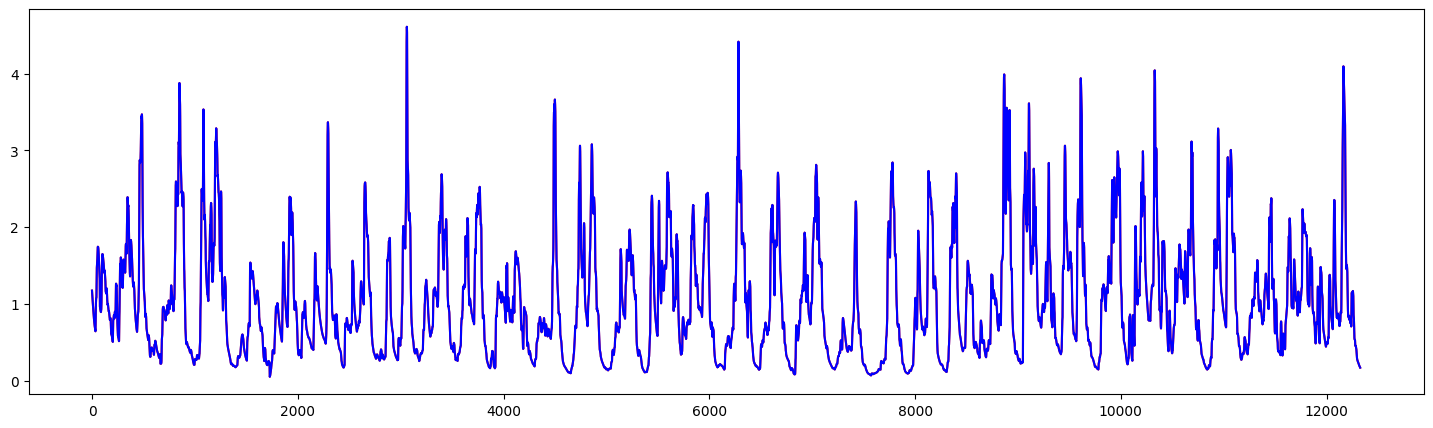

In [11]:
import numpy as np
import matplotlib.pyplot as plt

ob= np.load("/scratch/data/PUR_DATA/test/Region_1/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")
bs= np.load("/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_1/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1980_2014/baseflow.npy")


plt.figure(figsize=(18,5))
plt.plot(ob[0,365:,-1],color="red")
plt.plot(bs[:,0],color="blue")
plt.show()

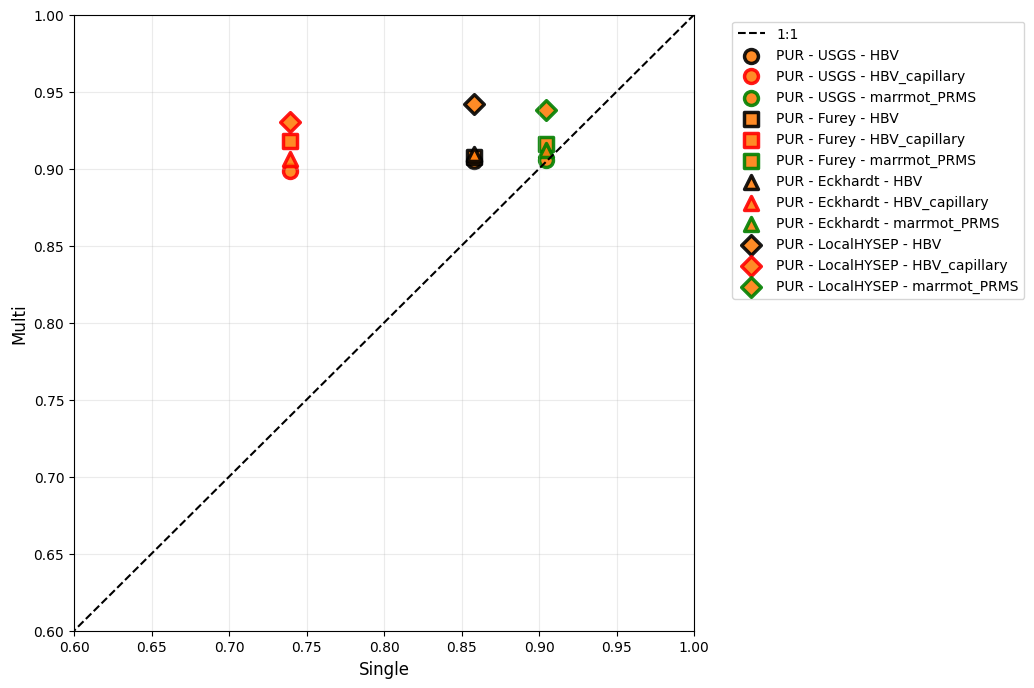

In [10]:
import matplotlib.pyplot as plt
import os
import pandas as pd


# ============================================================
# SETTINGS
# ============================================================

DATA_DIR = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/Total_Recharge_Basin_wise_csv_2/"
)


# ============================================================
# COLORS FOR TEST
# ============================================================

test_colors = {
    "PUB": "tab:blue",
    "PUR": "tab:orange"
}


# ============================================================
# MARKERS FOR METHOD
# ============================================================

method_markers = {
    "USGS": "o",
    "Furey": "s",
    "Eckhardt": "^",
    "LocalHYSEP": "D"
}


# ============================================================
# OUTLINE COLORS FOR MODEL
# ============================================================

model_edgecolors = {
    "HBV": "black",
    "HBV_capillary": "red",
    "marrmot_PRMS": "green"
}


# ============================================================
# STORE RESULTS
# ============================================================

results = []


# ============================================================
# LOOP FILES
# ============================================================

for file in os.listdir(DATA_DIR):

    if not file.startswith(
        "annual_recharge_"
    ):
        continue

    if not file.endswith(
        ".csv"
    ):
        continue


    # --------------------------------------------------------
    # Read data
    # --------------------------------------------------------

    path = os.path.join(
        DATA_DIR,
        file
    )

    data = pd.read_csv(
        path
    )


    # --------------------------------------------------------
    # Calculate correlations
    # --------------------------------------------------------

    corr_single = data[
        "tiff"
    ].corr(
        data["sim_old"]
    )

    corr_multi = data[
        "tiff"
    ].corr(
        data["sim_new"]
    )


    # ========================================================
    # PARSE FILENAME
    # ========================================================

    # Example:
    #
    # annual_recharge_PUR_Furey_HBV_2000_2013.csv
    #
    # annual_recharge_PUB_Eckhardt_HBV_capillary_2000_2013.csv
    # annual_recharge_PUR_Eckhardt_marrmot_PRMS_2000_2013.csv


    # --------------------------------------------------------
    # TEST
    # --------------------------------------------------------

    if "_PUB_" in file:

        test = "PUB"

    elif "_PUR_" in file:

        test = "PUR"

    else:

        continue


    # --------------------------------------------------------
    # METHOD
    # --------------------------------------------------------

    method = None

    for m in method_markers:

        if f"_{m}_" in file:

            method = m
            break


    if method is None:

        continue


    # --------------------------------------------------------
    # MODEL
    # --------------------------------------------------------

    if "_HBV_capillary_" in file:

        model = "HBV_capillary"

    elif "_marrmot_PRMS_" in file:

        model = "marrmot_PRMS"

    elif "_HBV_" in file:

        model = "HBV"

    else:

        continue


    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    results.append(
        {
            "file": file,
            "test": test,
            "method": method,
            "model": model,
            "Corr_Single": corr_single,
            "Corr_Multi": corr_multi
        }
    )


# ============================================================
# CREATE DATAFRAME
# ============================================================

metrics = pd.DataFrame(
    results
)


# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(8, 8)
)


# ============================================================
# 1:1 LINE
# ============================================================

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    linewidth=1.5,
    label="1:1"
)


# ============================================================
# PLOT EACH TEST + METHOD + MODEL
# ============================================================

for test in [
    "PUB",
    "PUR"
]:

    for method in [
        "USGS",
        "Furey",
        "Eckhardt",
        "LocalHYSEP"
    ]:

        for model in [
            "HBV",
            "HBV_capillary",
            "marrmot_PRMS"
        ]:


            # ------------------------------------------------
            # Select data
            # ------------------------------------------------

            subset = metrics[
                (metrics["test"] == test)
                &
                (metrics["method"] == method)
                &
                (metrics["model"] == model)
            ]


            if len(subset) == 0:

                continue


            # ------------------------------------------------
            # Scatter
            # ------------------------------------------------

            plt.scatter(

                subset["Corr_Single"],

                subset["Corr_Multi"],

                # Fill = PUB/PUR
                color=test_colors[test],

                # Shape = method
                marker=method_markers[method],

                # Outline = model
                edgecolors=model_edgecolors[model],

                linewidths=2.5,

                s=100,

                alpha=0.9,

                label=(
                    f"{test} - "
                    f"{method} - "
                    f"{model}"
                )
            )


# ============================================================
# AXES
# ============================================================

plt.xlim(
    0.6,
    1
)

plt.ylim(
    0.6,
    1
)


plt.xlabel(
    "Single",
    fontsize=12
)

plt.ylabel(
    "Multi",
    fontsize=12
)


# ============================================================
# LEGEND
# ============================================================

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)


# ============================================================
# GRID
# ============================================================

plt.grid(
    alpha=0.25
)


plt.show()

PUB, HBV, USGS


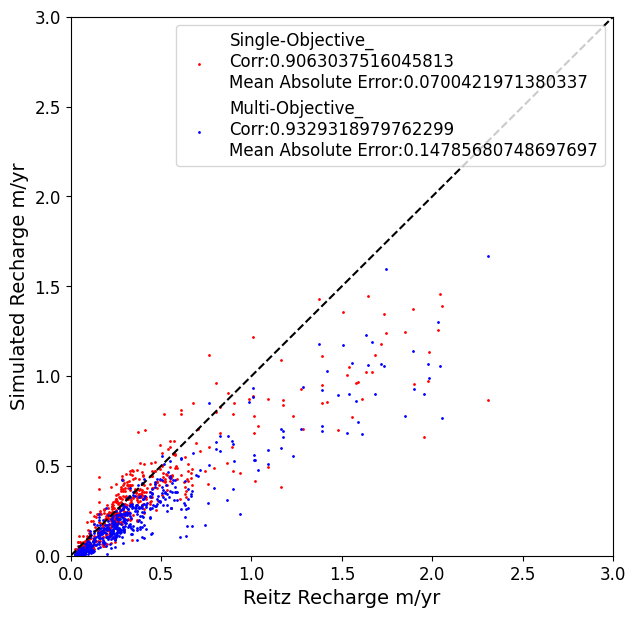

PUB, HBV_capillary, USGS


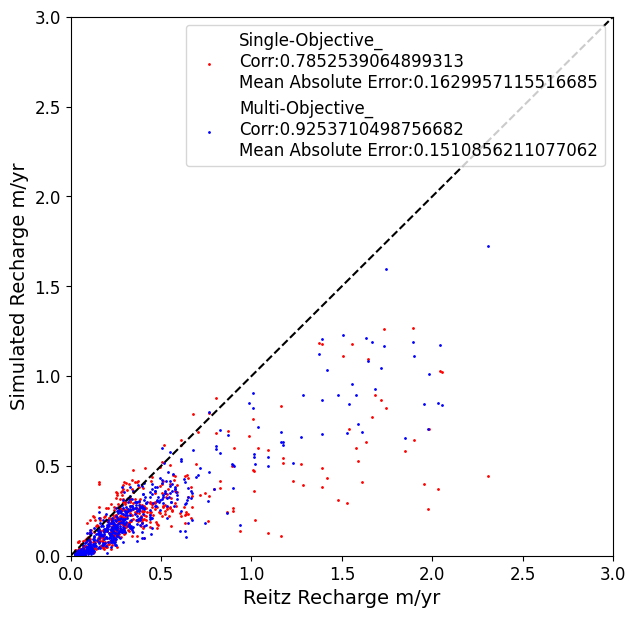

PUB, marrmot_PRMS, USGS


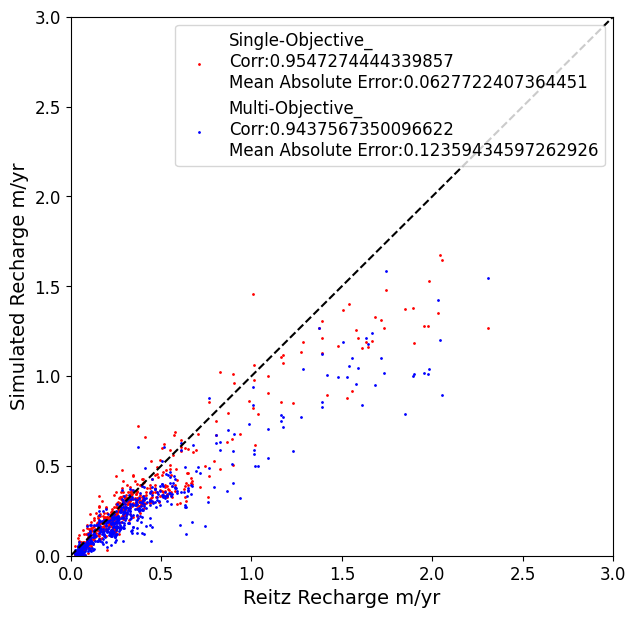

PUB, HBV, Furey


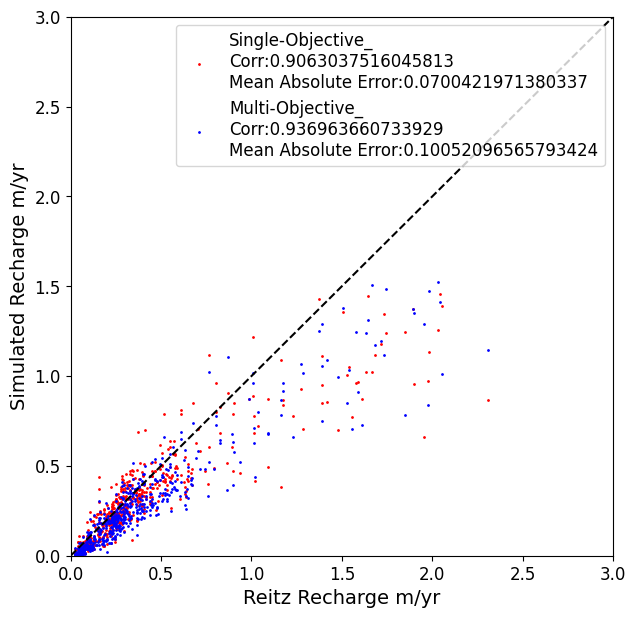

PUB, HBV_capillary, Furey


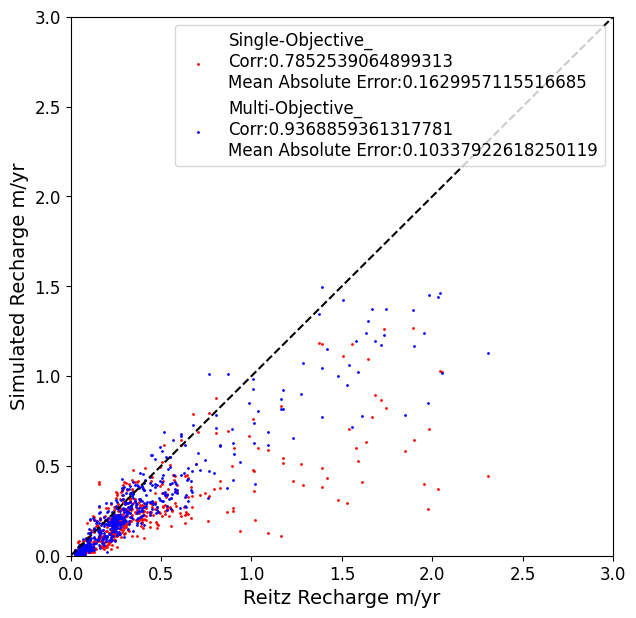

PUB, marrmot_PRMS, Furey


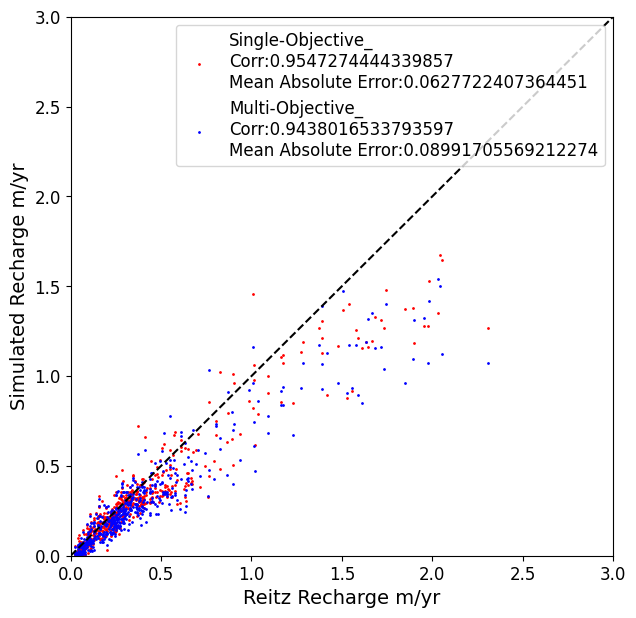

PUB, HBV, Eckhardt


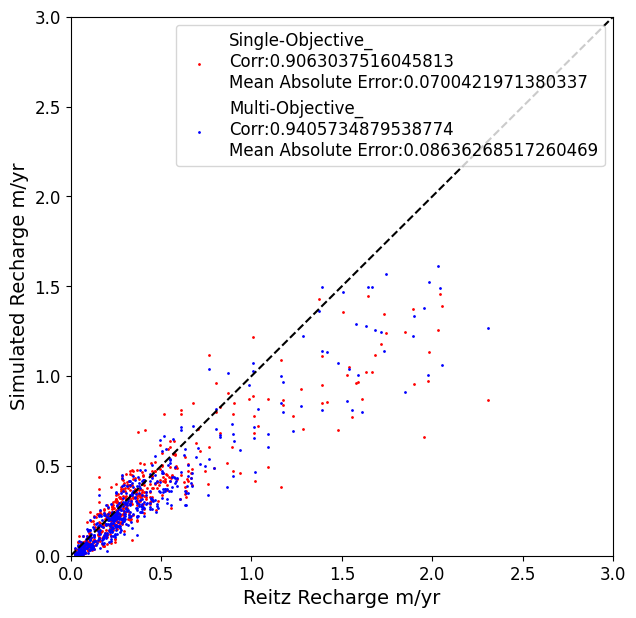

PUB, HBV_capillary, Eckhardt


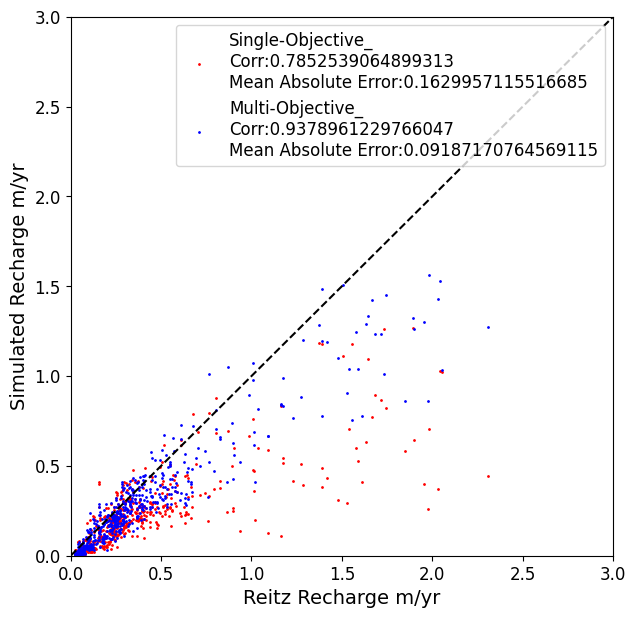

PUB, marrmot_PRMS, Eckhardt


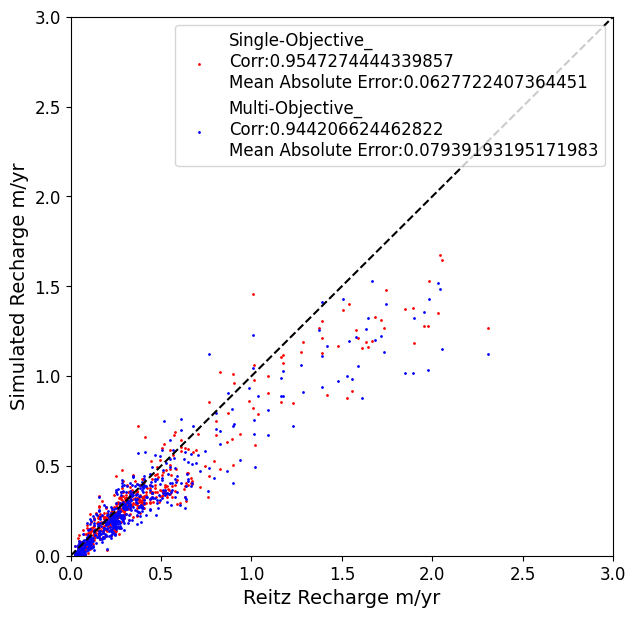

PUB, HBV, LocalHYSEP


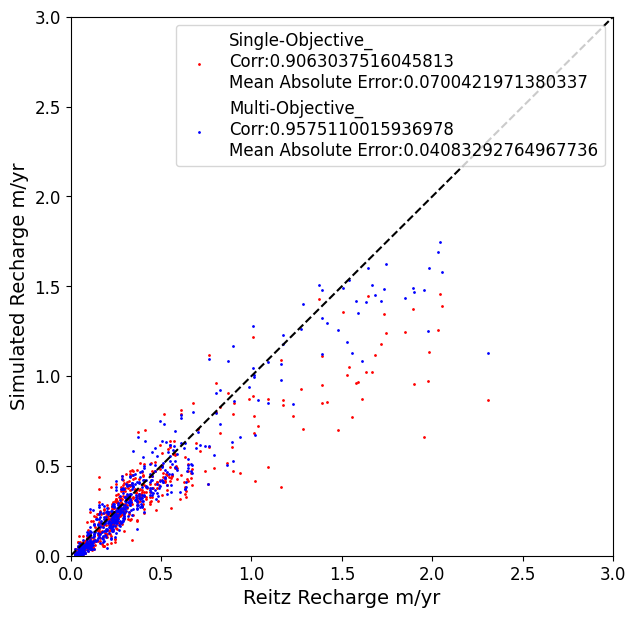

PUB, HBV_capillary, LocalHYSEP


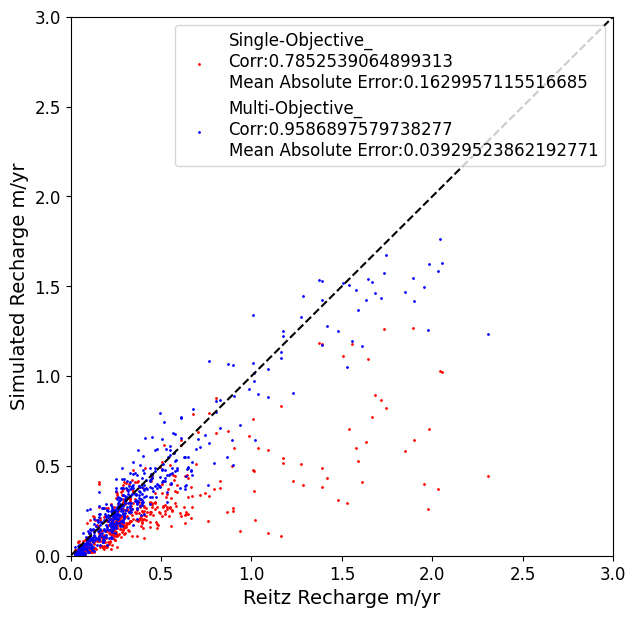

PUB, marrmot_PRMS, LocalHYSEP


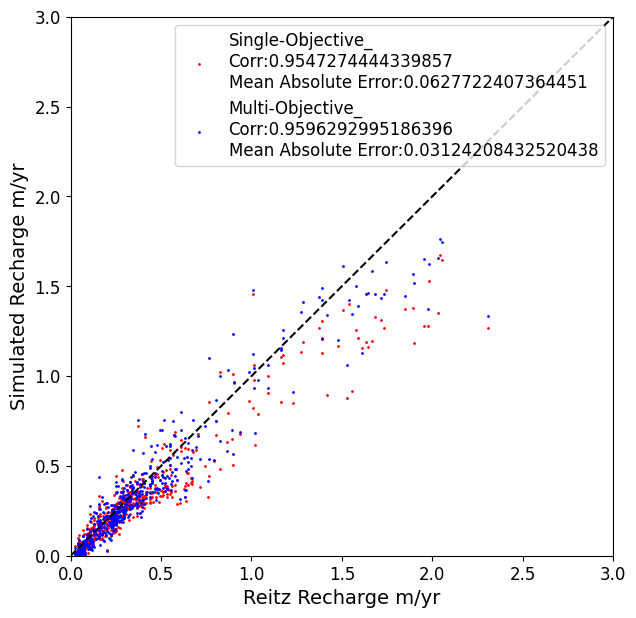

PUR, HBV, USGS


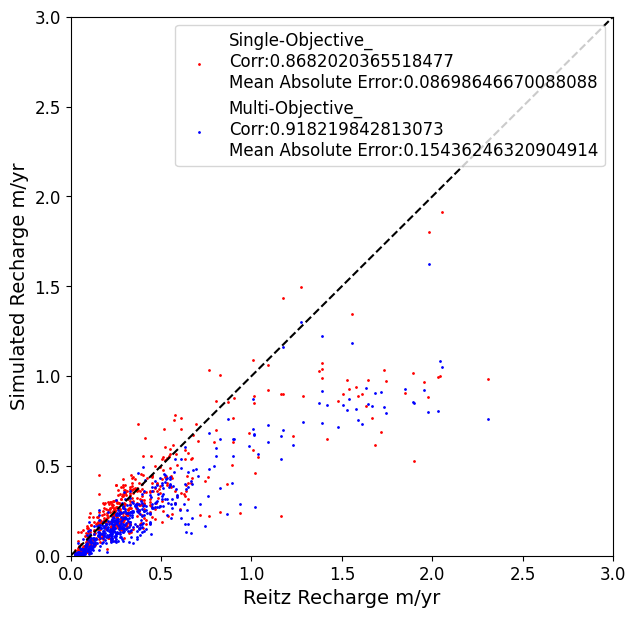

PUR, HBV_capillary, USGS


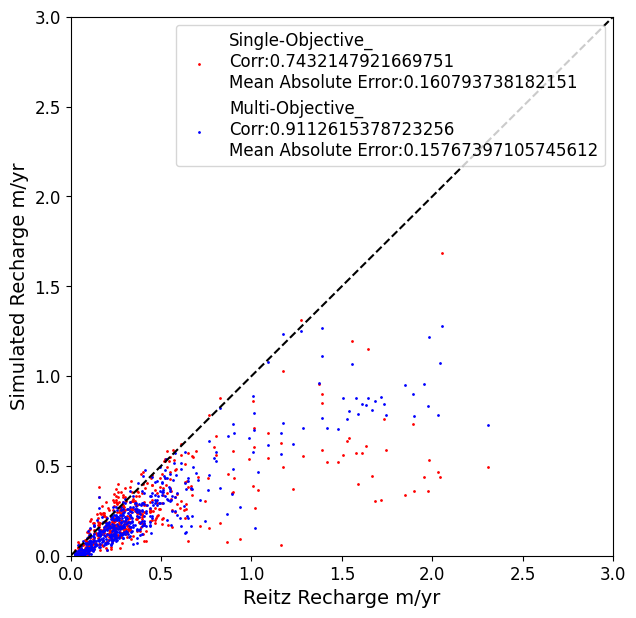

PUR, marrmot_PRMS, USGS


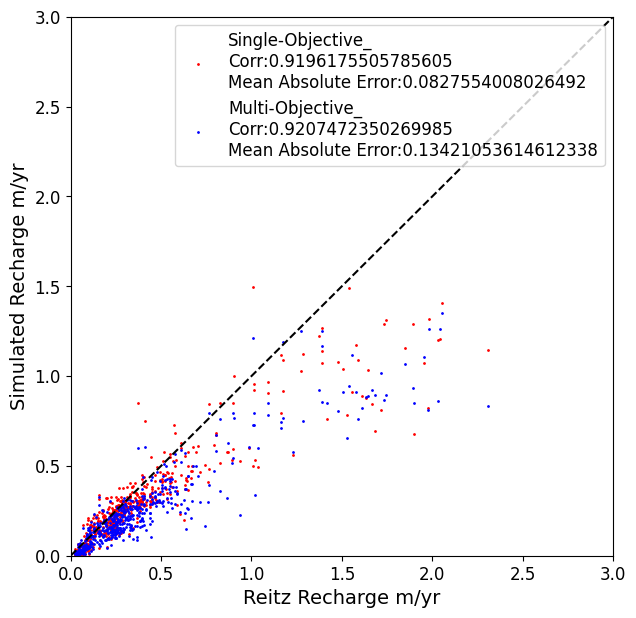

PUR, HBV, Furey


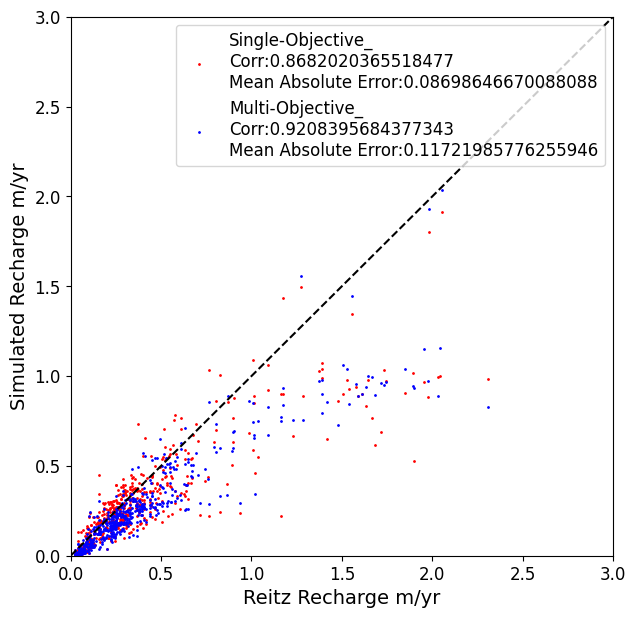

PUR, HBV_capillary, Furey


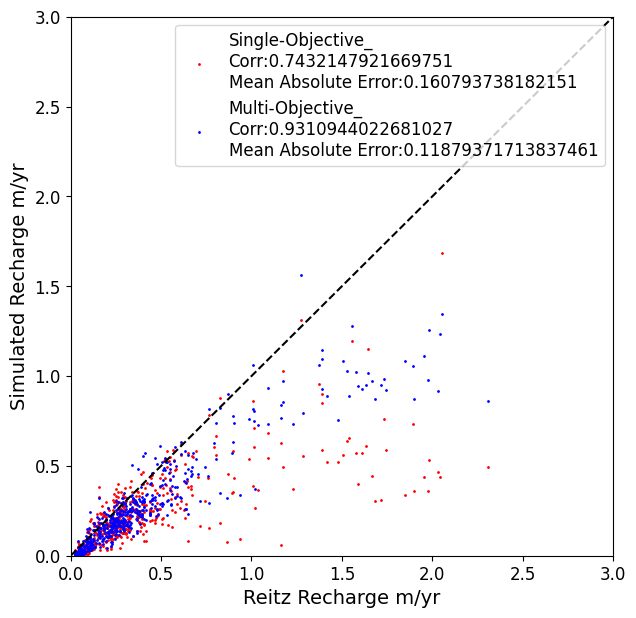

PUR, marrmot_PRMS, Furey


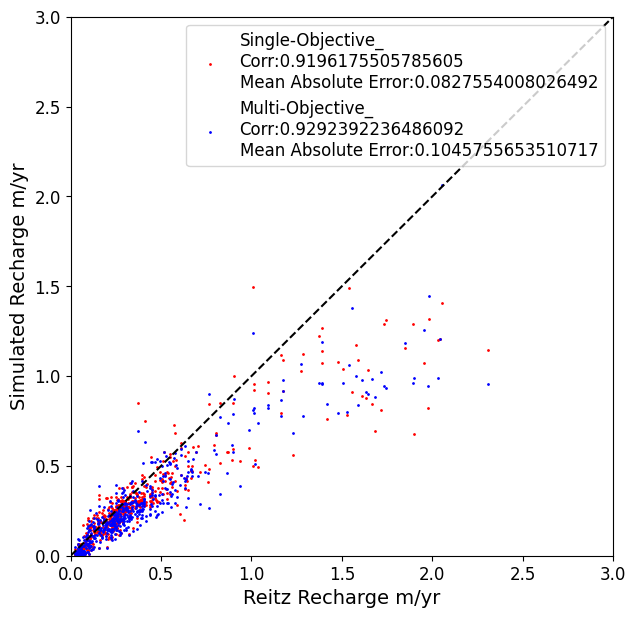

PUR, HBV, Eckhardt


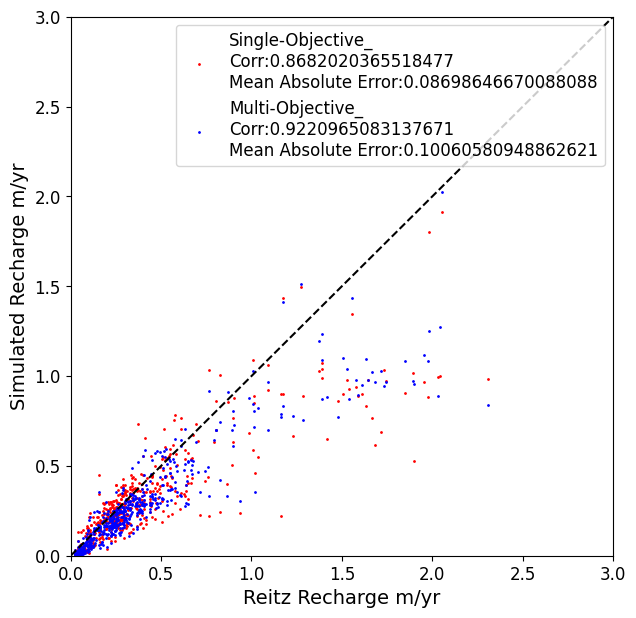

PUR, HBV_capillary, Eckhardt


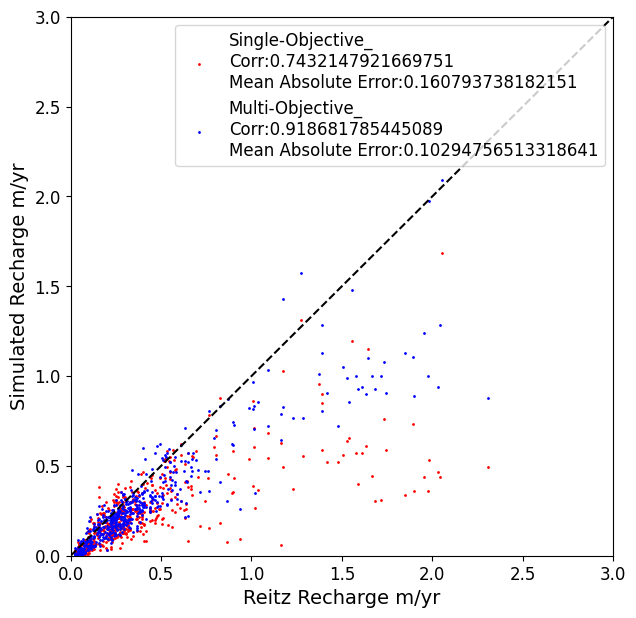

PUR, marrmot_PRMS, Eckhardt


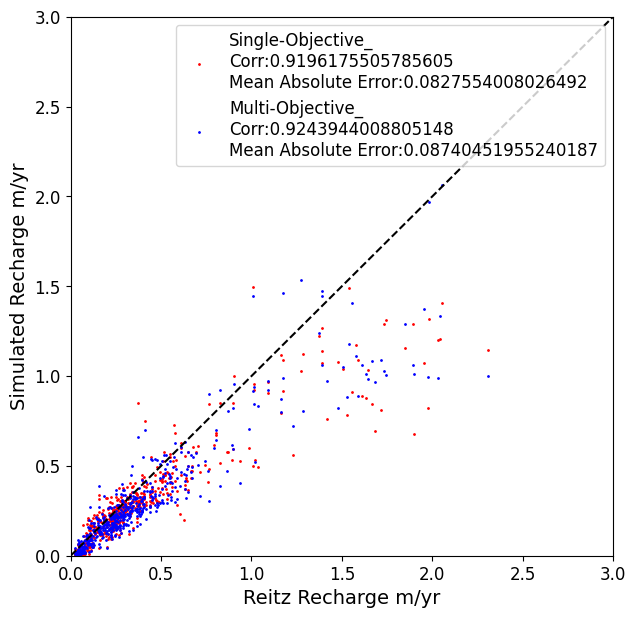

PUR, HBV, LocalHYSEP


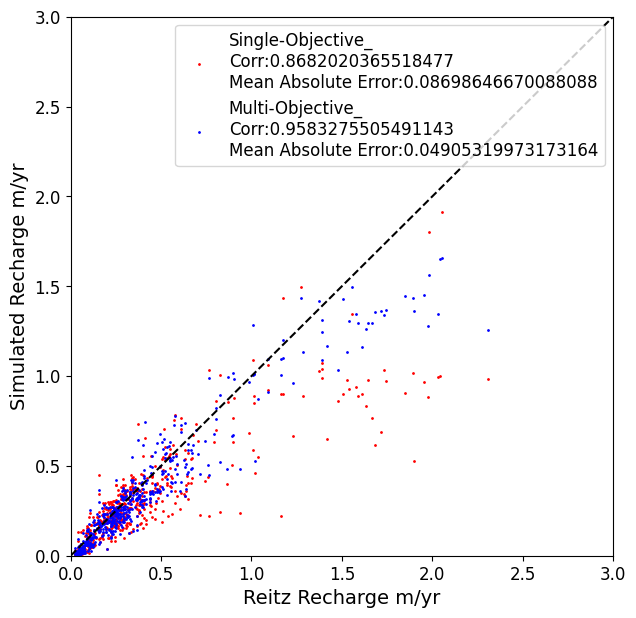

PUR, HBV_capillary, LocalHYSEP


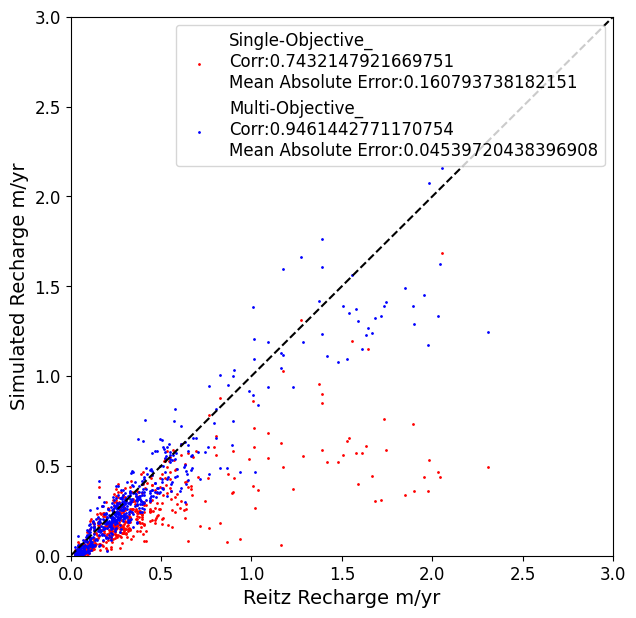

PUR, marrmot_PRMS, LocalHYSEP


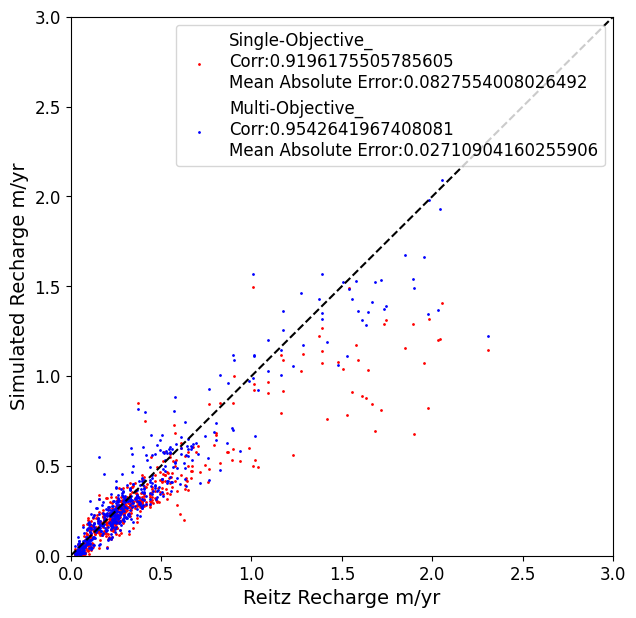

,year,gageid,tiff,sim_old,sim_new
0,2000,1022500,0.396791,0.386595,0.317022
1,2001,1022500,0.115087,0.180112,0.147758
2,2002,1022500,0.501151,0.350615,0.306672
3,2003,1022500,0.508841,0.428730,0.381771
4,2004,1022500,0.342088,0.313713,0.242307
...,...,...,...,...,...
178411,2009,14400000,0.874877,0.558388,0.886263
178412,2010,14400000,1.786468,0.701878,1.590541
178413,2011,14400000,1.214065,0.565352,1.075133
178414,2012,14400000,1.921728,0.673350,1.293597


In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt


DATA_DIR = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/Total_Recharge_Basin_wise_csv_2/"
)


# ============================================================
# COLORS FOR TEST
# ============================================================

test_colors = {
    "PUB": "tab:blue",
    "PUR": "tab:orange"
}


# ============================================================
# MARKERS FOR METHOD
# ============================================================

method_markers = {
    "USGS": "o",
    "Furey": "s",
    "Eckhardt": "^",
    "LocalHYSEP": "D"
}


# ============================================================
# OUTLINE COLORS FOR MODEL
# ============================================================

model_edgecolors = {
    "HBV": "black",
    "HBV_capillary": "red",
    "marrmot_PRMS": "green"
}



dfs= []

# ============================================================
# LOOP FILES
# ============================================================
for test in test_colors.keys():
    for method in method_markers.keys():
        for model in model_edgecolors.keys():
            df= pd.read_csv(os.path.join(DATA_DIR,f'annual_recharge_{test}_{method}_{model}_2000_2013.csv'))
            avg_df = (
                df.groupby("gageid")[["tiff", "sim_old", "sim_new"]]
                .mean()
                .reset_index()
            )
            print(f"{test}, {model}, {method}")
            plt.figure(figsize=(7,7))
            plt.scatter(avg_df['tiff'], avg_df['sim_old'], color= 'red', s=1, label= f'Single-Objective_\nCorr:{avg_df.tiff.corr(avg_df.sim_old)}\nMean Absolute Error:{(avg_df.tiff-avg_df.sim_old).mean()}')
            plt.scatter(avg_df['tiff'], avg_df['sim_new'], color= 'blue', s=1, label= f'Multi-Objective_\nCorr:{avg_df.tiff.corr(avg_df.sim_new)}\nMean Absolute Error:{(avg_df.tiff-avg_df.sim_new).mean()}')
            plt.plot([0, 3],[0, 3], "k--")
            plt.xlim(0,3)
            plt.xlabel('Reitz Recharge m/yr', fontsize=14)
            plt.ylabel('Simulated Recharge m/yr', fontsize=14)
            plt.ylim(0,3)
            plt.legend(fontsize=12)
            plt.xticks(fontsize=12)
            plt.yticks(fontsize=12)
            plt.show()
            dfs.append(df)
data= pd.concat(dfs, ignore_index=True)
data

In [50]:
avg_df = (
    df.groupby("gageid")[["tiff", "sim_old", "sim_new"]]
      .mean()
      .reset_index()
)

display(avg_df)

,gageid,tiff,sim_old,sim_new
0,1022500,0.522157,0.450205,0.534807
1,1031500,0.551370,0.402973,0.578567
2,1047000,0.632674,0.392895,0.489840
3,1052500,0.665188,0.472265,0.594919
4,1054200,0.794329,0.615247,0.689056
...,...,...,...,...
526,14309500,0.413217,0.751378,0.802683
527,14316700,0.569768,0.727303,0.804724
528,14325000,0.900411,0.849068,1.114890
529,14362250,0.156317,0.338236,0.547017


In [ ]:
"""
Compare dPS historical recharge with the USGS effective-recharge product of
Reitz et al. (2017), 2000-2013, for EITHER basin set:

    DATASET = "huc12_4231"   -> 4231 HUC12 basins (Daymet historical runs)
    DATASET = "gauged_2003"  -> 2003 gauged basins (Daymet historical runs)

Reviewer #2 (Line 245): "Are the recharge estimates derived in the present
study comparable in magnitude, spatial patterns, and climatic sensitivity to
those reported by the USGS?"

Basin averaging
---------------
Preferred: exact area averages using basin polygons (set SHP_PATH and
SHP_ID_COL below; requires geopandas). Overlapping/nested basins (typical for
gauged catchments) are handled correctly because each polygon gets its own
pixel mask. Each yearly grid is read once, so the zonal pass is fast.
Fallback: if SHP_PATH is None, the raster is averaged in a circular window of
radius WINDOW_KM around each basin centroid.

Units: the RC_eff grids are in METERS/yr (diagnostic: median 0.0237,
max 3.88) -> REITZ_UNIT_SCALE = 1000 converts to mm/yr.
"""

from pathlib import Path
import json
import pickle
import os

os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

import numpy as np


# ===========================================================================
# Configuration
# ===========================================================================
DATASET = "gauged_2003"            # "huc12_4231" or "gauged_2003"

BASE_DIR    = Path("D:/DR")
FIG_OUT_DIR = BASE_DIR / "evaluation_figures"
FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

REITZ_DIR = Path("D:/Data_psu/Reitz_et_al_2017_rech")

# Which Reitz product to compare against:
#   "effective" -> EffRecharge_{Y}/{Y}/RC_eff_{Y}.tiff  (P - ET - quickflow)
#   "total"     -> TotalRecharge_{Y}/{Y}/RC_{Y}.tif     (total recharge)
REITZ_PRODUCT = "total"

PRODUCT = {
    "effective": dict(folder="EffRecharge_{y}", fname="RC_eff_{y}.tiff",
                      stem="RC_eff_{y}", label="effective recharge"),
    "total":     dict(folder="TotalRecharge_{y}", fname="RC_{y}.tif",
                      stem="RC_{y}", label="total recharge"),
}[REITZ_PRODUCT]

YEAR_FROM, YEAR_TO = 2000, 2013
REITZ_UNIT_SCALE = 1000.0          # grids are meters/yr -> mm/yr
WINDOW_KM = 5.0                    # centroid-window fallback radius
MIN_P_MM  = 50.0

CFG = {
    "huc12_4231": dict(
        cache   = BASE_DIR / "data" / "hist_RP_4231_cache.pkl",
        attr    = BASE_DIR / "data" / "ts_data_4231" /
                  "attr_HUC12_4231_grid_clip_20250224.npy",
        # Directory of per-basin HUC12 shapefiles. If a file has no "huc12"
        # attribute column, the basin ID is taken from the digits in its
        # FILE NAME. Basins without a polygon are filled with the
        # centroid-window average automatically.
        shp     = Path("H:/Frshd/inputs/PGML_STemp_results/inputs/"
                       "inputs_2003/shp_separate_208_recharge/"
                       "huc12_shp_separate"),
        shp_id  = "huc12",
        id_zfill = 12,             # HUC12 codes are 12-digit strings
        tag     = "HUC12 (4231 basins)",
    ),
    "gauged_2003": dict(
        cache   = BASE_DIR / "data" / "hist_RP_2003_cache.pkl",
        attr    = BASE_DIR / "data" / "ts_2003basins" /
                  "attr2003_mswep_03122024.npy",
        # GAGES-II basin boundaries. This is a DIRECTORY: all *.shp inside
        # (bas_ref_all, bas_nonref_* by aggregated ecoregion) are read and
        # merged, then matched to the 2003 basins by GAGE_ID.
        shp     = Path("D:/Data_psu/GAGES_II/boundaries_shapefiles_by_aggeco/"
                       "boundaries-shapefiles-by-aggeco"),
        shp_id  = "GAGE_ID",
        id_zfill = 8,              # USGS gage IDs are 8-digit strings
        tag     = "gauged basins (2003)",
    ),
}[DATASET]

ATTR_ID_COL = "site_no_int"        # attr column holding the basin/gage ID


# ===========================================================================
# Reitz yearly files and band loading
# ===========================================================================
import rasterio
from rasterio.warp import transform as rio_transform
from rasterio.features import geometry_mask
from rasterio.windows import from_bounds as window_from_bounds


def reitz_year_file(year):
    cand = REITZ_DIR / PRODUCT["folder"].format(y=year) / f"{year}" / \
           PRODUCT["fname"].format(y=year)
    if cand.exists():
        return cand
    hits = sorted(REITZ_DIR.rglob(PRODUCT["stem"].format(y=year) + ".tif*"))
    return hits[0] if hits else None


def load_band_mm(src):
    """Read raster as mm/yr with NaN for nodata; multi-band = monthly sum."""
    nod = src.nodata
    bands = []
    for b in range(1, src.count + 1):
        a = src.read(b).astype(np.float64)
        if nod is not None:
            a[a == nod] = np.nan
        a[a < 0] = np.nan
        sc = src.scales[b - 1] if src.scales else 1.0
        of = src.offsets[b - 1] if src.offsets else 0.0
        if sc not in (None, 0, 1.0) or (of not in (None, 0.0)):
            a = a * (sc or 1.0) + (of or 0.0)
        bands.append(a)
    band = bands[0] if len(bands) == 1 else np.nansum(np.stack(bands), axis=0)
    if len(bands) > 1:
        allnan = ~np.any([np.isfinite(x) for x in bands], axis=0)
        band[allnan] = np.nan
    return band * REITZ_UNIT_SCALE


# ===========================================================================
# 1. dPS means and basin attributes
# ===========================================================================
with open(CFG["cache"], "rb") as f:
    H = pickle.load(f)
selr  = (H["years_r"] >= YEAR_FROM) & (H["years_r"] <= YEAR_TO)
self_ = (H["years_f"] >= YEAR_FROM) & (H["years_f"] <= YEAR_TO)
R_dps  = np.nanmean(H["R_yearly_ens"][selr], axis=0)
Pbar   = np.nanmean(H["P_yearly"][self_], axis=0)
PETbar = np.nanmean(H["PET_yearly"][self_], axis=0)
phi    = np.where(Pbar >= MIN_P_MM, PETbar / Pbar, np.nan)
L      = R_dps.size
print(f"[{CFG['tag']}] dPS mean recharge {YEAR_FROM}-{YEAR_TO}: "
      f"median {np.nanmedian(R_dps):.0f} mm/yr over {L} basins")

attr_path = CFG["attr"]
name_path = attr_path.with_name(attr_path.stem + "_name.json")
if not name_path.exists():
    name_path = attr_path.with_name(attr_path.stem + "_name")
with open(name_path, "r", encoding="utf-8") as f:
    a_names = json.load(f)
attr = np.load(attr_path)
lat = attr[:, a_names.index("lat")].astype(float)
lon = attr[:, a_names.index("lon")].astype(float)
assert lat.size == L, f"attr basins {lat.size} != cache basins {L}"

basin_ids = None
if ATTR_ID_COL in a_names:
    basin_ids = np.array([str(int(v)).zfill(CFG["id_zfill"])
                          for v in attr[:, a_names.index(ATTR_ID_COL)]])


# ===========================================================================
# 2. Reitz basin values: polygon zonal means, or centroid-window fallback
# ===========================================================================
def read_basin_polygons(shp_path, shp_id_col):
    """Read one shapefile, or merge ALL *.shp under a directory. Handles both
    multi-basin files (GAGES-II regional files with an ID column) and
    one-shapefile-per-basin layouts: if a file lacks the ID column, the ID is
    taken from the longest digit sequence in the FILE NAME."""
    import re
    import geopandas as gpd
    import pandas as pd
    shp_path = Path(shp_path)
    if shp_path.is_dir():
        files = sorted(shp_path.rglob("*.shp"))
        if not files:
            raise FileNotFoundError(f"No .shp files under {shp_path}")
        parts, ref_crs = [], None
        n_named, n_skipped = 0, 0
        for k, fp in enumerate(files):
            g = gpd.read_file(fp)
            if shp_id_col not in g.columns:
                digits = re.findall(r"\d+", fp.stem)
                if digits:
                    g[shp_id_col] = max(digits, key=len)
                    n_named += 1
                else:
                    n_skipped += 1
                    continue
            g = g[[shp_id_col, g.geometry.name]]
            if ref_crs is None:
                ref_crs = g.crs
            elif g.crs != ref_crs:
                g = g.to_crs(ref_crs)
            parts.append(g)
            if len(files) <= 20:
                print(f"  read {fp.name}: {len(g)} basin(s)")
            elif (k + 1) % 1000 == 0:
                print(f"  ... {k + 1}/{len(files)} shapefiles read")
        if not parts:
            raise RuntimeError(f"No usable shapefiles under {shp_path} (need a "
                               f"'{shp_id_col}' column or digits in filenames)")
        if n_named:
            print(f"  {n_named} file(s) had no '{shp_id_col}' column — ID taken "
                  "from filename digits")
        if n_skipped:
            print(f"  [skip] {n_skipped} file(s): no ID column and no digits "
                  "in filename")
        gdf = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs=ref_crs)
        n0 = len(gdf)
        gdf = gdf.drop_duplicates(subset=shp_id_col, keep="first")
        print(f"Merged {len(parts)} shapefiles: {n0} features, "
              f"{len(gdf)} unique {shp_id_col}")
        return gdf
    return gpd.read_file(shp_path)


def zonal_means_all_years(shp_path, shp_id_col):
    """Exact area averages per basin polygon for every yearly grid.
    Handles nested/overlapping polygons (one pixel mask per polygon)."""
    gdf = read_basin_polygons(shp_path, shp_id_col)
    if shp_id_col not in gdf.columns:
        raise KeyError(f"Column '{shp_id_col}' not in shapefile; available: "
                       f"{list(gdf.columns)}")
    gdf["_id"] = gdf[shp_id_col].astype(str).str.strip().str.zfill(CFG["id_zfill"])
    if basin_ids is None:
        raise RuntimeError(f"attr file has no '{ATTR_ID_COL}' column; cannot "
                           "match polygons to basin order")
    id_to_row = {b: i for i, b in enumerate(basin_ids)}
    hits = gdf["_id"].map(id_to_row)
    matched = gdf[hits.notna()].copy()
    matched["_row"] = hits[hits.notna()].astype(int)
    print(f"Matched {len(matched)} / {L} basins to polygons "
          f"({len(gdf)} features in shapefile)")

    first = reitz_year_file(YEAR_FROM)
    with rasterio.open(first) as src:
        matched = matched.to_crs(src.crs)
        # Precompute one (window, mask) per polygon on the common grid.
        pre = []
        for row_i, geom in zip(matched["_row"], matched.geometry):
            if geom is None or geom.is_empty:
                continue
            w = window_from_bounds(*geom.bounds, transform=src.transform)
            r0 = max(0, int(np.floor(w.row_off)))
            c0 = max(0, int(np.floor(w.col_off)))
            r1 = min(src.height, int(np.ceil(w.row_off + w.height)) + 1)
            c1 = min(src.width,  int(np.ceil(w.col_off + w.width)) + 1)
            if r1 <= r0 or c1 <= c0:
                continue
            wt = src.window_transform(((r0, r1), (c0, c1)))
            m = geometry_mask([geom.__geo_interface__], out_shape=(r1 - r0, c1 - c0),
                              transform=wt, invert=True, all_touched=False)
            if not m.any():   # polygon smaller than a pixel -> take its cell
                m[:] = False
                m[min(m.shape[0] - 1, m.shape[0] // 2),
                  min(m.shape[1] - 1, m.shape[1] // 2)] = True
            pre.append((row_i, r0, r1, c0, c1, m))
        ref_shape = (src.height, src.width)
    print(f"Precomputed pixel masks for {len(pre)} polygons")

    sums = np.zeros(L)
    cnts = np.zeros(L)
    for yy in range(YEAR_FROM, YEAR_TO + 1):
        fp = reitz_year_file(yy)
        if fp is None:
            print(f"  [warn] no {REITZ_PRODUCT}-recharge file for {yy} — skipped")
            continue
        with rasterio.open(fp) as src:
            assert (src.height, src.width) == ref_shape, \
                f"{fp.name}: grid differs from {YEAR_FROM} grid"
            band = load_band_mm(src)
        year_vals = np.full(L, np.nan)
        for row_i, r0, r1, c0, c1, m in pre:
            block = band[r0:r1, c0:c1][m]
            if np.isfinite(block).any():
                year_vals[row_i] = np.nanmean(block)
        good = np.isfinite(year_vals)
        sums[good] += year_vals[good]
        cnts[good] += 1
        print(f"  {fp.name}: valid {good.sum()}/{L}, "
              f"median {np.nanmedian(year_vals):.0f} mm/yr")
    out = np.where(cnts > 0, sums / np.maximum(cnts, 1), np.nan)
    has_poly = np.zeros(L, dtype=bool)
    for row_i, *_ in pre:
        has_poly[row_i] = True
    return out, has_poly


def centroid_window_means_all_years():
    out_years = []
    printed = [False]
    for yy in range(YEAR_FROM, YEAR_TO + 1):
        fp = reitz_year_file(yy)
        if fp is None:
            print(f"  [warn] no {REITZ_PRODUCT}-recharge file for {yy} — skipped")
            continue
        vals = np.full(L, np.nan)
        with rasterio.open(fp) as src:
            xs, ys = rio_transform("EPSG:4326", src.crs, lon.tolist(), lat.tolist())
            xs, ys = np.asarray(xs), np.asarray(ys)
            if src.crs.is_projected:
                hx = WINDOW_KM * 1000.0 / abs(src.transform.a)
                hy = WINDOW_KM * 1000.0 / abs(src.transform.e)
            else:
                hx = (WINDOW_KM / 111.0 / np.cos(np.deg2rad(np.nanmean(lat)))) \
                     / abs(src.transform.a)
                hy = (WINDOW_KM / 111.0) / abs(src.transform.e)
            hx, hy = max(1, int(round(hx))), max(1, int(round(hy)))
            band = load_band_mm(src)
            if not printed[0]:
                print(f"Reitz raster: {src.width}x{src.height}, CRS {src.crs}, "
                      f"{src.count} band(s), window +/-{hx}x{hy} px, "
                      f"unit scale {REITZ_UNIT_SCALE}")
                printed[0] = True
            from rasterio.transform import rowcol
            rows, cols = rowcol(src.transform, xs.tolist(), ys.tolist())
            rows = np.atleast_1d(rows).astype(int)
            cols = np.atleast_1d(cols).astype(int)
            for i in range(L):
                r, c = rows[i], cols[i]
                if not (0 <= r < src.height and 0 <= c < src.width):
                    continue
                blk = band[max(0, r - hy):r + hy + 1, max(0, c - hx):c + hx + 1]
                if np.isfinite(blk).any():
                    vals[i] = np.nanmean(blk)
        out_years.append(vals)
        print(f"  {fp.name}: valid {np.isfinite(vals).sum()}/{L}, "
              f"median {np.nanmedian(vals):.0f} mm/yr")
    if not out_years:
        raise FileNotFoundError(f"No {REITZ_PRODUCT}-recharge files found "
                                f"under {REITZ_DIR}")
    return np.nanmean(np.stack(out_years, axis=0), axis=0)


if CFG["shp"] is not None:
    R_reitz, has_poly = zonal_means_all_years(CFG["shp"], CFG["shp_id"])
    method = "basin-polygon area average"
    miss = ~has_poly
    if miss.any():
        print(f"[note] {miss.sum()} basin(s) without a polygon — filling with "
              f"{WINDOW_KM:.0f}-km centroid-window averages")
        R_win = centroid_window_means_all_years()
        R_reitz = np.where(miss, R_win, R_reitz)
        method = (f"polygon average; centroid-window fill for "
                  f"{miss.sum()} basins")
else:
    R_reitz = centroid_window_means_all_years()
    method = f"{WINDOW_KM:.0f}-km centroid window average"
print(f"Averaging method: {method}")

ok = np.isfinite(R_dps) & np.isfinite(R_reitz)
print(f"Basins with valid Reitz value: {ok.sum()} / {L}")


# ===========================================================================
# 3. Agreement statistics
# ===========================================================================
x, y = R_reitz[ok], R_dps[ok]
r_pear  = np.corrcoef(x, y)[0, 1]
r_spear = np.corrcoef(np.argsort(np.argsort(x)), np.argsort(np.argsort(y)))[0, 1]
bias    = np.mean(y - x)
pbias   = 100.0 * np.sum(y - x) / np.sum(x)
ratio   = np.median(y / np.where(x > 0, x, np.nan))
print(f"\n=== dPS vs Reitz et al. (2017) {PRODUCT['label']}, "
      f"{YEAR_FROM}-{YEAR_TO}, {CFG['tag']} ===")
print(f"Pearson r  : {r_pear:.3f}")
print(f"Spearman r : {r_spear:.3f}")
print(f"Mean bias  : {bias:+.1f} mm/yr ({pbias:+.1f}%)")
print(f"Median ratio dPS/Reitz: {ratio:.2f}")
for lo, hi, tag in ((0, 1, "humid (phi<1)"), (1, 2, "transitional (1-2)"),
                    (2, 99, "arid (phi>2)")):
    s = ok & (phi >= lo) & (phi < hi)
    if s.sum() > 10:
        rr = np.corrcoef(R_reitz[s], R_dps[s])[0, 1]
        pb = 100.0 * np.sum(R_dps[s] - R_reitz[s]) / np.sum(R_reitz[s])
        print(f"  {tag:20s}: n={s.sum():5d}, r={rr:.3f}, bias={pb:+.0f}%")


# ===========================================================================
# 4. Scatter figure
# ===========================================================================
AX_FS = 24
fig, ax = plt.subplots(figsize=(12, 11))
plt.subplots_adjust(left=0.11, bottom=0.1, right=0.97, top=0.91)
sc = ax.scatter(x, y, s=30, alpha=0.4, c=phi[ok], cmap="RdYlBu_r",
                vmin=0.3, vmax=3.0, linewidths=0)
cb = plt.colorbar(sc, ax=ax)
cb.set_label("Aridity index  φ = PET/P (–)", fontsize=AX_FS - 2)
cb.ax.tick_params(labelsize=AX_FS - 6)
lim = np.nanpercentile(np.concatenate([x, y]), 99.5)
ax.plot([0, lim], [0, lim], color="k", lw=1.5)
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.set_xlabel(f"Reitz et al. (2017) {PRODUCT['label']} (mm/yr)", fontsize=AX_FS)
ax.set_ylabel("δPS recharge (mm/yr)", fontsize=AX_FS)
ax.set_title(f"δPS vs USGS {PRODUCT['label']}, {YEAR_FROM}–{YEAR_TO}\n"
             f"{CFG['tag']}, {method}\n"
             f"r = {r_pear:.2f}, Mean bias = {bias:+.00f} mm/yr, n = {ok.sum()}",
             fontsize=AX_FS - 4)
ax.tick_params(axis="both", labelsize=AX_FS)
ax.grid(True, ls=":")
out = FIG_OUT_DIR / f"dPS_vs_Reitz_{REITZ_PRODUCT}_{DATASET}_{YEAR_FROM}_{YEAR_TO}.png"
plt.savefig(out, dpi=300)
plt.close("all")
print(f"\nSaved figure: {out}")
print("END")

In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt


DATA_DIR = (
    "/home/s0shar47/scratch/"
    "Recharge_reitz/Total_Recharge_Basin_wise_csv_NSE_loss/"
)


# ============================================================
# COLORS FOR TEST
# ============================================================

test_colors = {
    # "PUB": "tab:blue",
    "PUR": "tab:orange"
}


# ============================================================
# MARKERS FOR METHOD
# ============================================================

method_markers = {
    # "USGS": "o",
    "Furey": "s",
    # "Eckhardt": "^",
    # "LocalHYSEP": "D"
}


# ============================================================
# OUTLINE COLORS FOR MODEL
# ============================================================

model_edgecolors = {
    "HBV": "black",
    # "HBV_capillary": "red",
    # "marrmot_PRMS": "green"
}



dfs= []

# ============================================================
# LOOP FILES
# ============================================================
for test in test_colors.keys():
    for method in method_markers.keys():
        for model in model_edgecolors.keys():
            df= pd.read_csv(os.path.join(DATA_DIR,f'annual_recharge_{test}_{method}_{model}_2000_2013.csv'))
            avg_df = (
                df.groupby("gageid")[["tiff", "sim_old", "sim_new"]]
                .mean()
                .reset_index()
            )
            print(f"{test}, {model}, {method}")
            # plt.figure(figsize=(7,7))
            # plt.scatter(avg_df['tiff'], avg_df['sim_old'], color= 'red', s=1, label= f'Single-Objective_\nCorr:{avg_df.tiff.corr(avg_df.sim_old)}\nMean Absolute Error:{(avg_df.tiff-avg_df.sim_old).mean()}')
            # plt.scatter(avg_df['tiff'], avg_df['sim_new'], color= 'blue', s=1, label= f'Multi-Objective_\nCorr:{avg_df.tiff.corr(avg_df.sim_new)}\nMean Absolute Error:{(avg_df.tiff-avg_df.sim_new).mean()}')
            # plt.plot([0, 3],[0, 3], "k--")
            # plt.xlim(0,3)
            # plt.xlabel('Reitz Recharge m/yr', fontsize=14)
            # plt.ylabel('Simulated Recharge m/yr', fontsize=14)
            # plt.ylim(0,3)
            # plt.legend(fontsize=12)
            # plt.xticks(fontsize=12)
            # plt.yticks(fontsize=12)
            # plt.show()
            dfs.append(df)
data= pd.concat(dfs, ignore_index=True)
data

PUR, HBV, Furey


,year,gageid,tiff,sim_old,sim_new
0,2000,1022500,0.396791,0.552516,0.546355
1,2001,1022500,0.115087,0.272374,0.284807
2,2002,1022500,0.501151,0.544413,0.518775
3,2003,1022500,0.508841,0.636949,0.617082
4,2004,1022500,0.342088,0.416680,0.422969
...,...,...,...,...,...
7429,2009,14400000,0.874877,0.524355,0.590139
7430,2010,14400000,1.786468,0.783070,1.054856
7431,2011,14400000,1.214065,0.567210,0.709733
7432,2012,14400000,1.921728,0.718002,0.927787


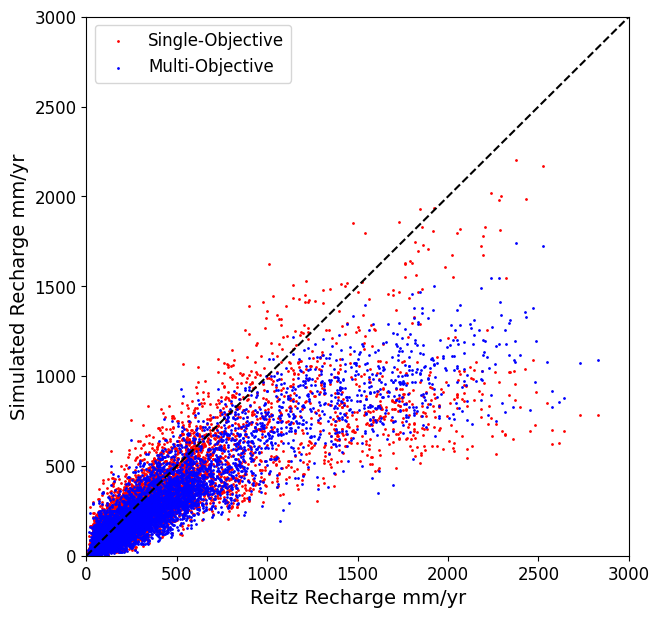

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,7))

plt.scatter(data['tiff']*1000, data['sim_old']*1000, color= 'red', s=1, label= 'Single-Objective')
plt.scatter(data['tiff']*1000, data['sim_new']*1000, color= 'blue', s=1, label= 'Multi-Objective')
plt.plot([0, 3000],[0, 3000], "k--")
plt.xlim(0,3000)
plt.xlabel('Reitz Recharge mm/yr', fontsize=14)
plt.ylabel('Simulated Recharge mm/yr', fontsize=14)
plt.ylim(0,3000)
plt.legend(fontsize=12)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.show()

Furey HBV


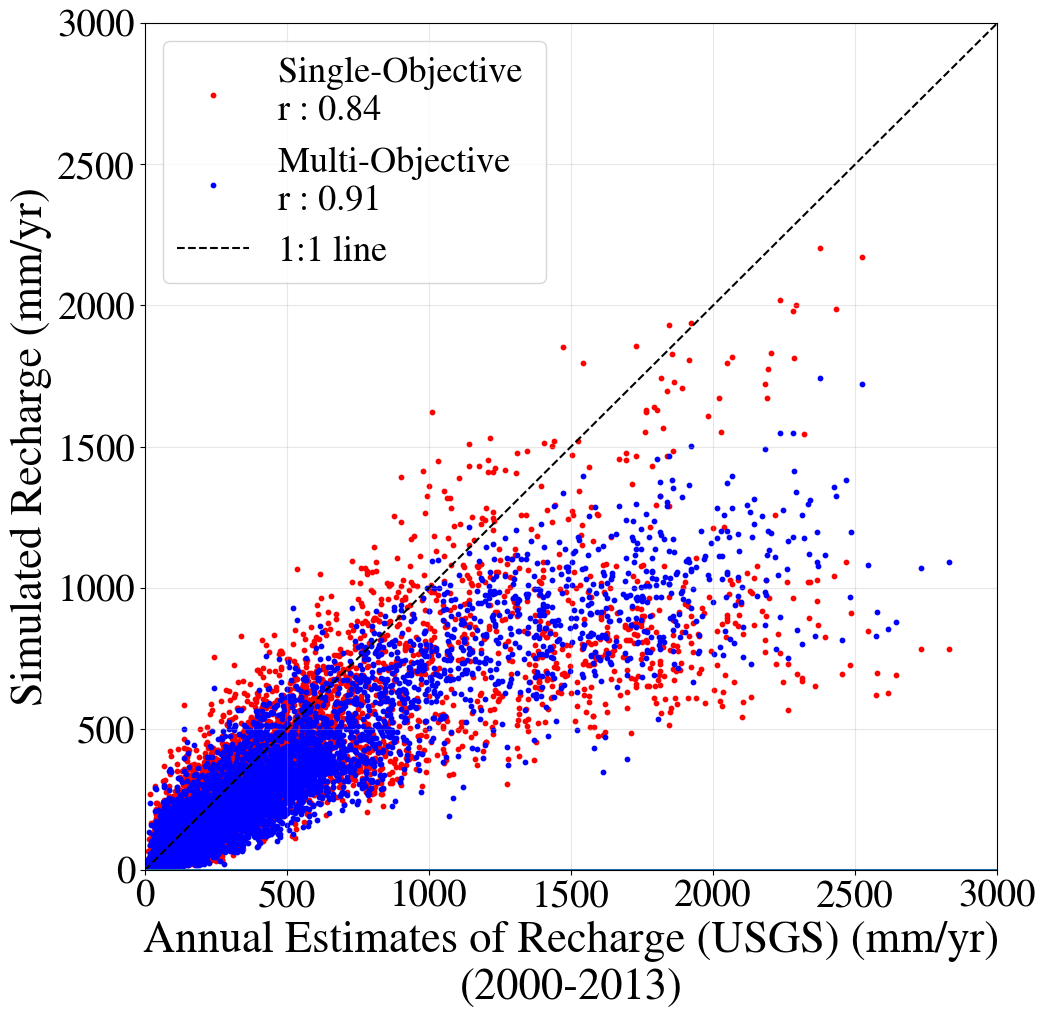

Furey marrmot_PRMS


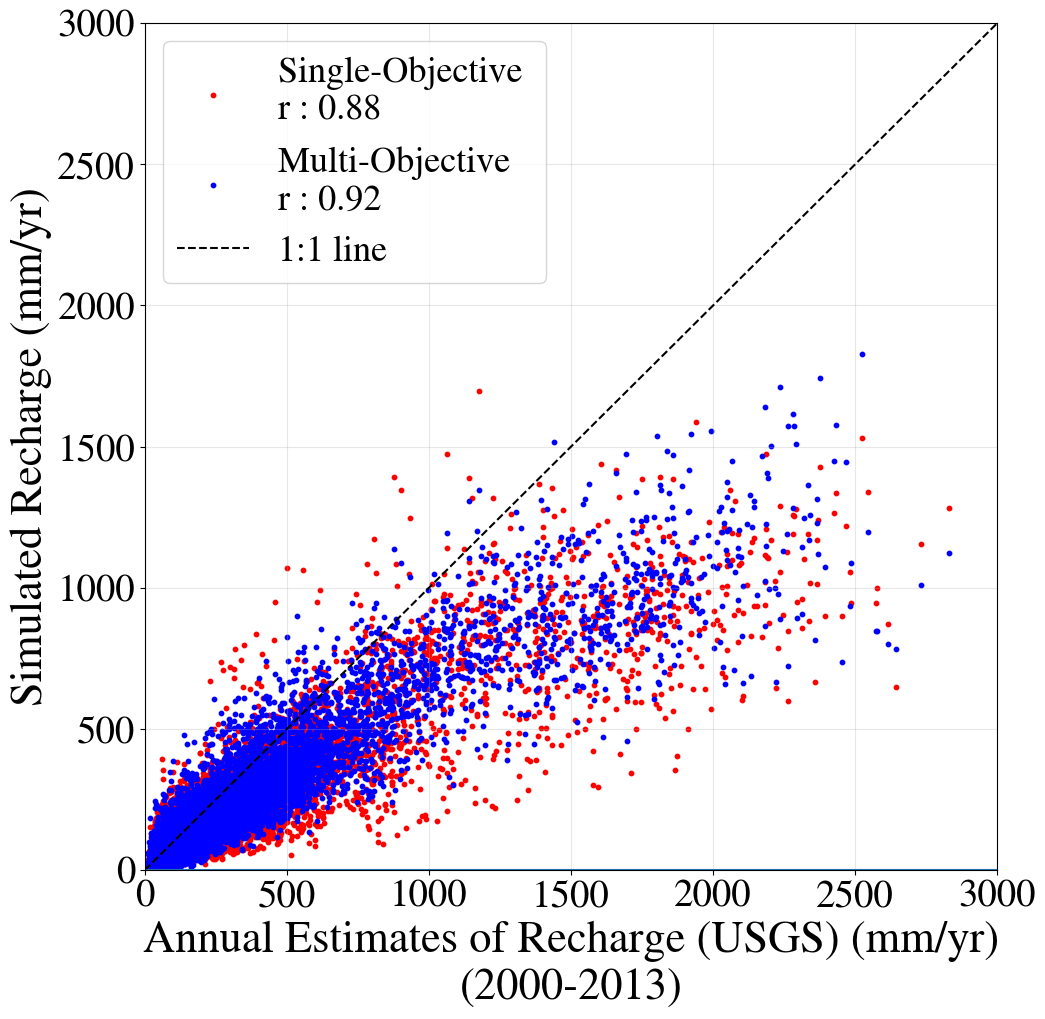

Furey HBV_capillary


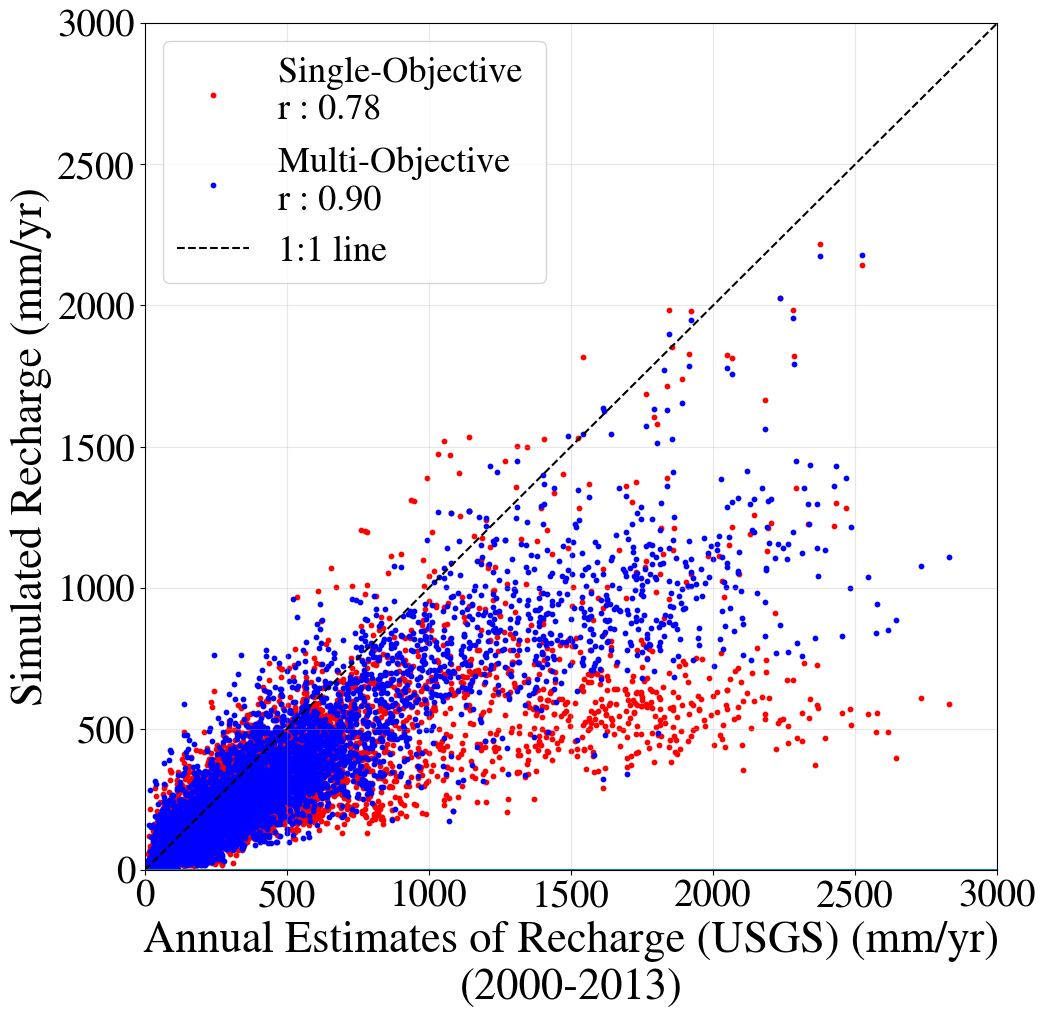

Eckhardt HBV


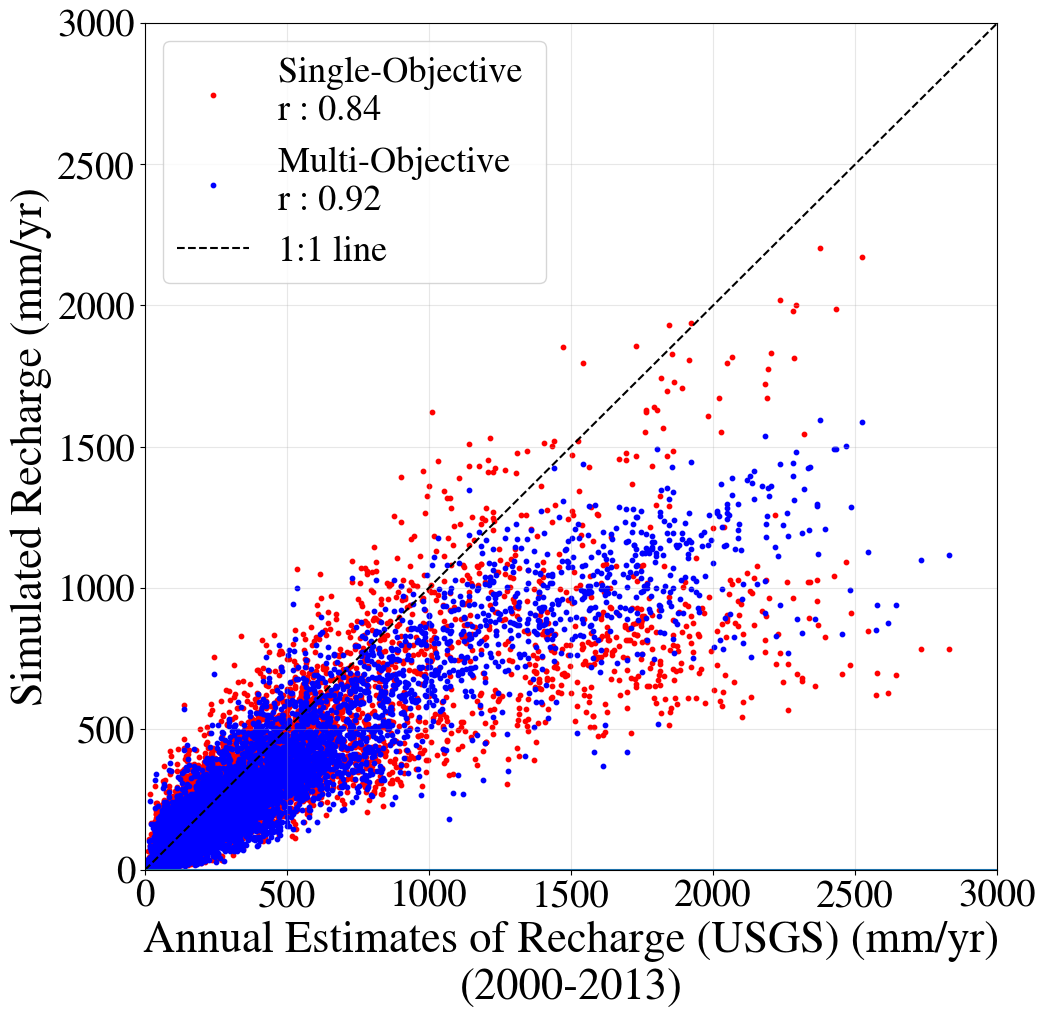

Eckhardt marrmot_PRMS


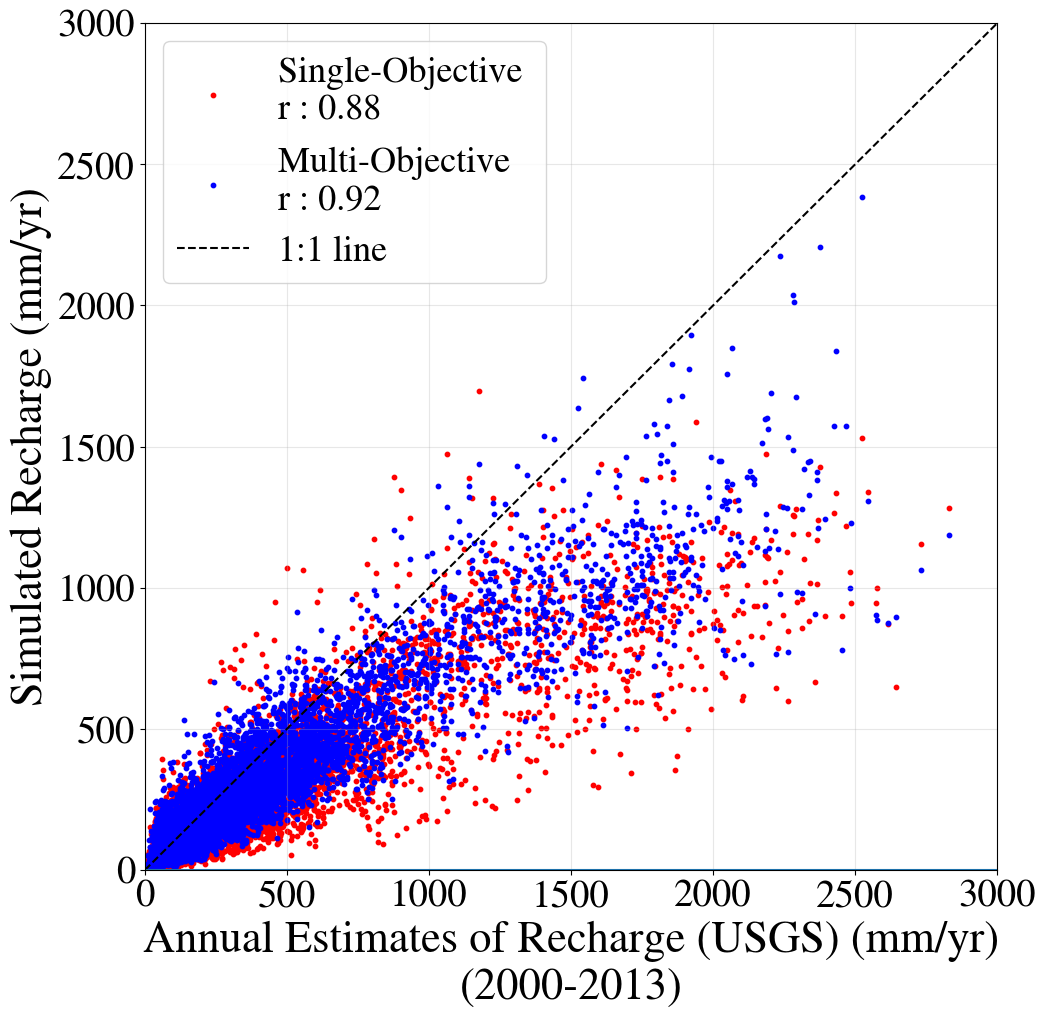

Eckhardt HBV_capillary


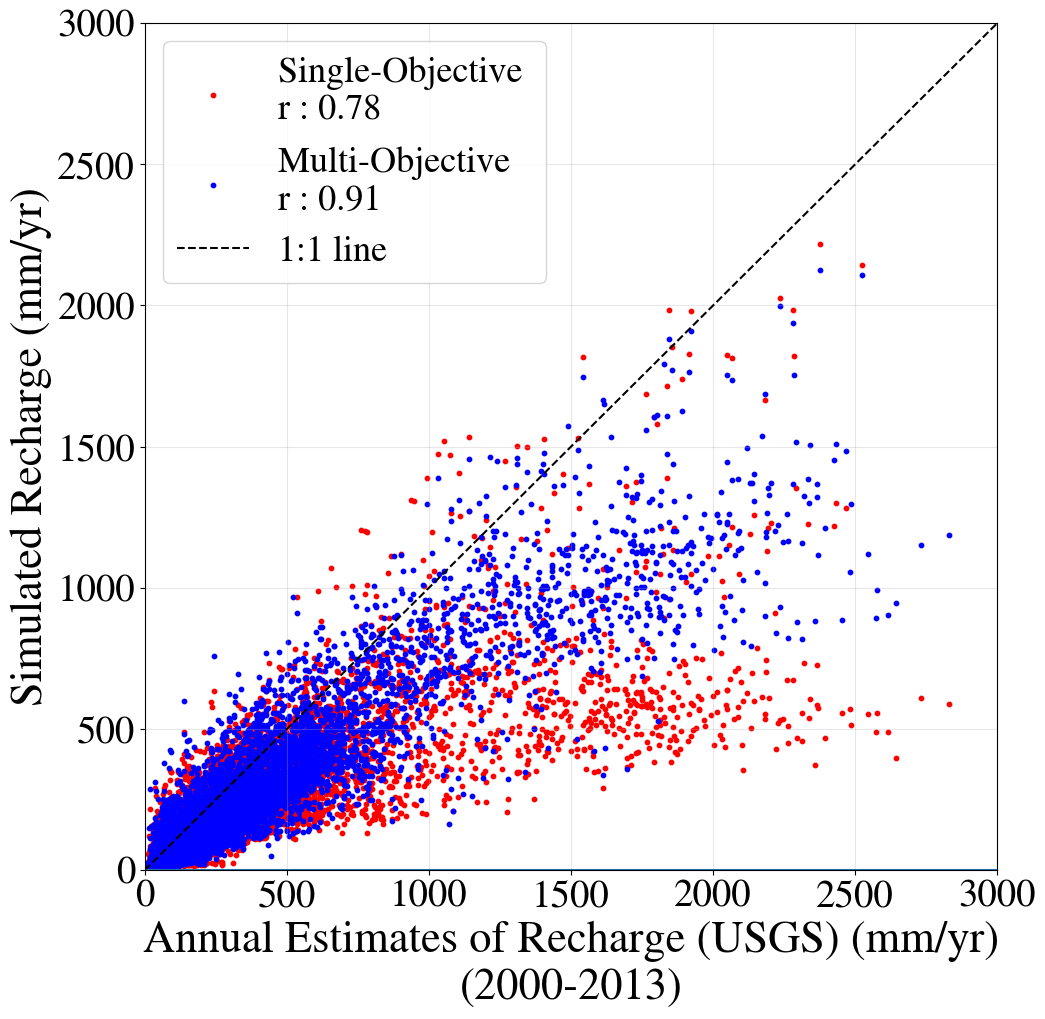

LocalHYSEP HBV


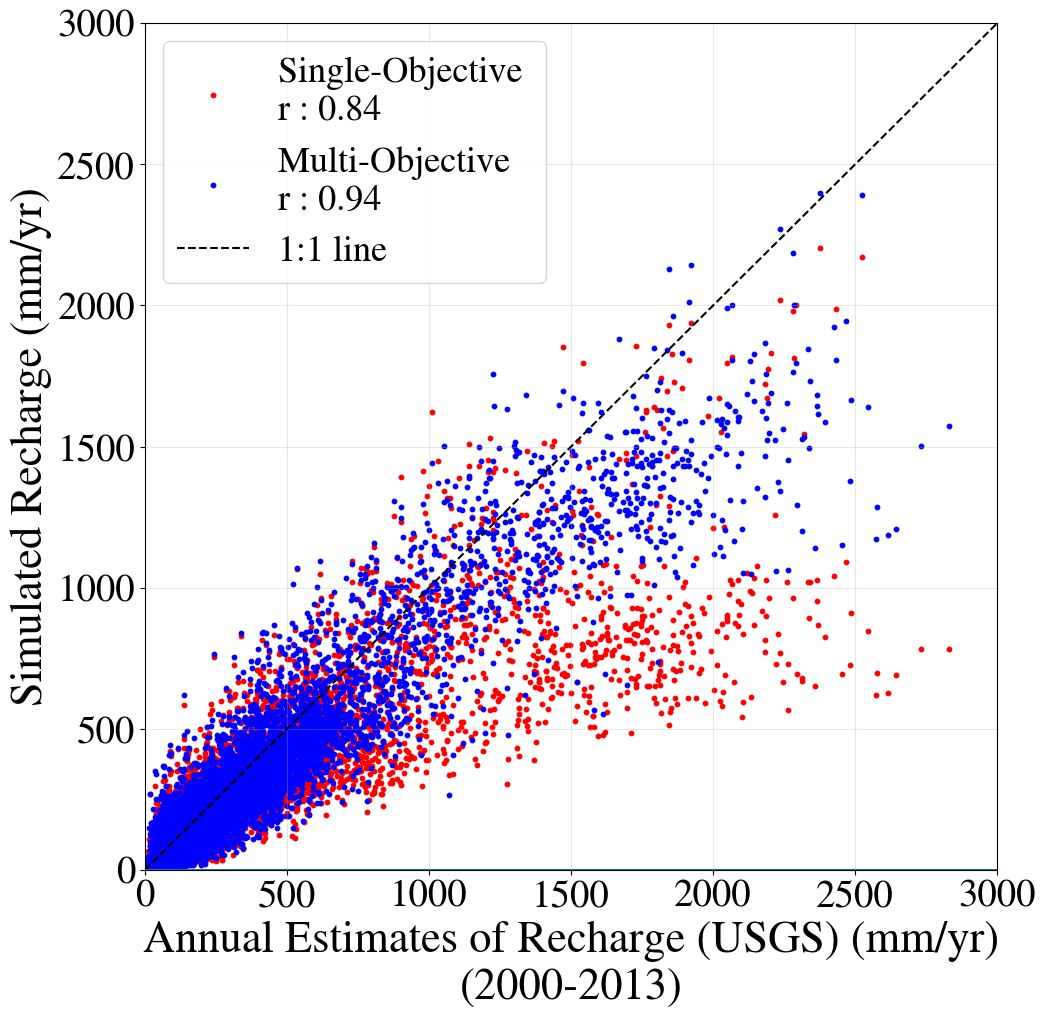

LocalHYSEP marrmot_PRMS


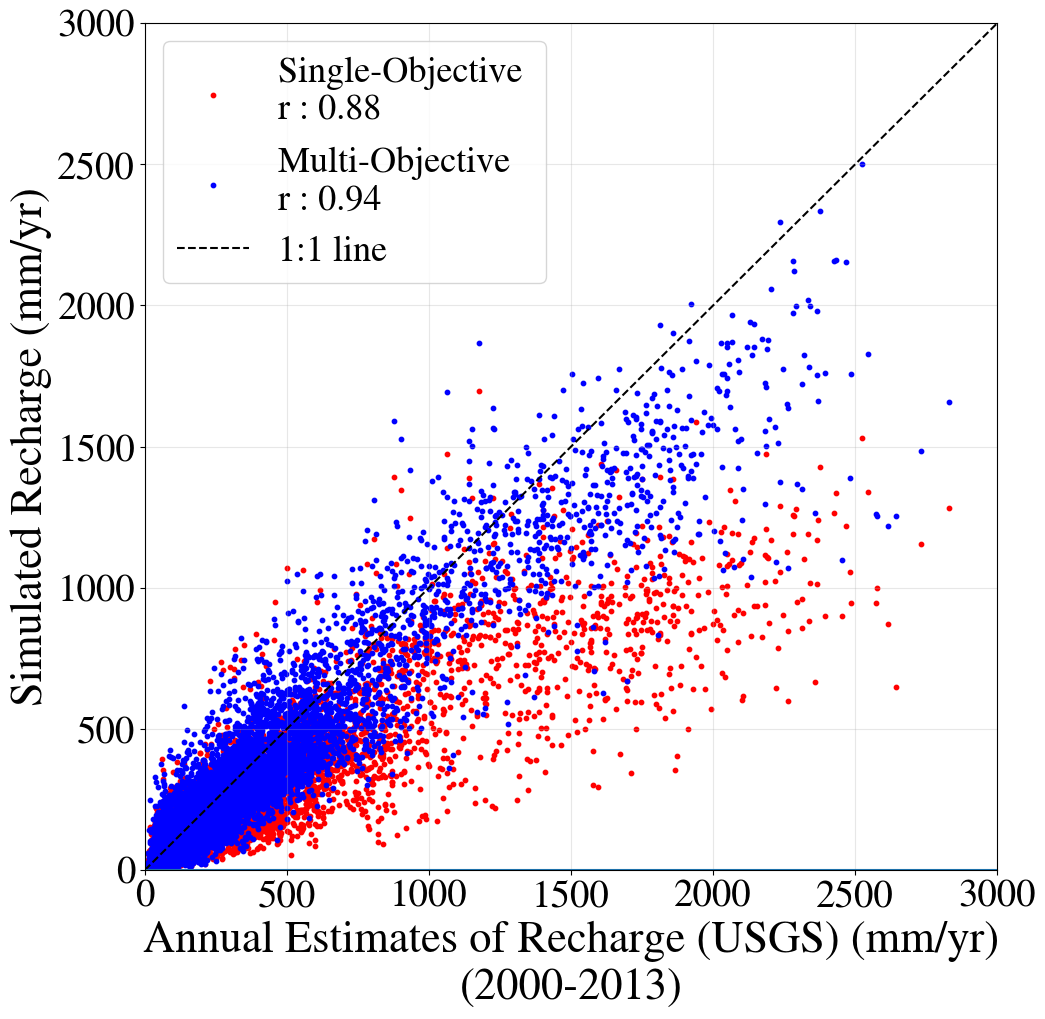

LocalHYSEP HBV_capillary


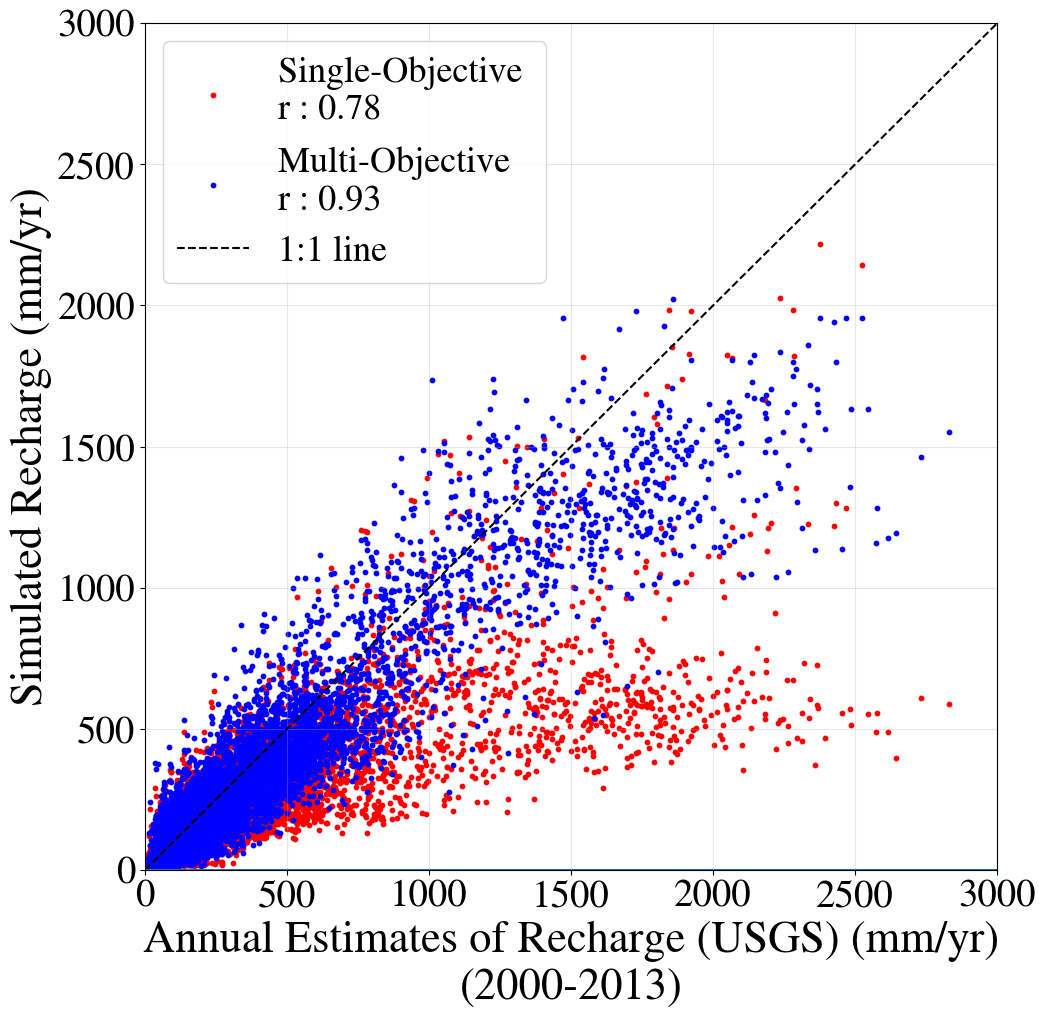

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
methods= [
        # 'USGS',
        'Furey',
        'Eckhardt',
        'LocalHYSEP'
            ]
models= [
    'HBV',
    'marrmot_PRMS',
    'HBV_capillary',
    
    ]
 
dfs=[]
for method in methods:
    for model in models:
        dd= pd.read_csv(f"/home/s0shar47/scratch/Recharge_reitz/Total_Recharge_Basin_wise_csv_NSE_loss/annual_recharge_PUR_{method}_{model}_2000_2013.csv")

        dd['tiff']= dd['tiff']*1000
        dd['sim_new']= dd['sim_new']*1000
        dd['sim_old']= dd['sim_old']*1000
        print(method,model)
       
        plt.rcParams['font.family']= 'Nimbus Roman'
        
        plt.figure(figsize=(11, 11))
        plt.scatter(dd['tiff'],dd['sim_old'],color='red', s=10, label= f"Single-Objective \nr : {dd['tiff'].corr(dd['sim_old']):.2f}")
        plt.scatter(dd['tiff'],dd['sim_new'],color='blue', s=10, label= f"Multi-Objective \nr : {dd['tiff'].corr(dd['sim_new']):.2f}")
        
        plt.plot([0, 3000], [0, 3000], 'k--', label='1:1 line')
        
        plt.xlabel('Annual Estimates of Recharge (USGS) (mm/yr)\n(2000-2013)',fontsize=32)
        plt.ylabel('Simulated Recharge (mm/yr)',fontsize=32)
        plt.axhline()
        plt.xlim(0,3000)
        plt.ylim(0,3000)
        plt.xticks(fontsize=28)
        plt.yticks(fontsize=28)
        plt.legend(fontsize=26)
        plt.grid(alpha=0.3)
        plt.show()

        # dfs.append(dd)
# df= pd.concat(dfs,ignore_index='True')
# df

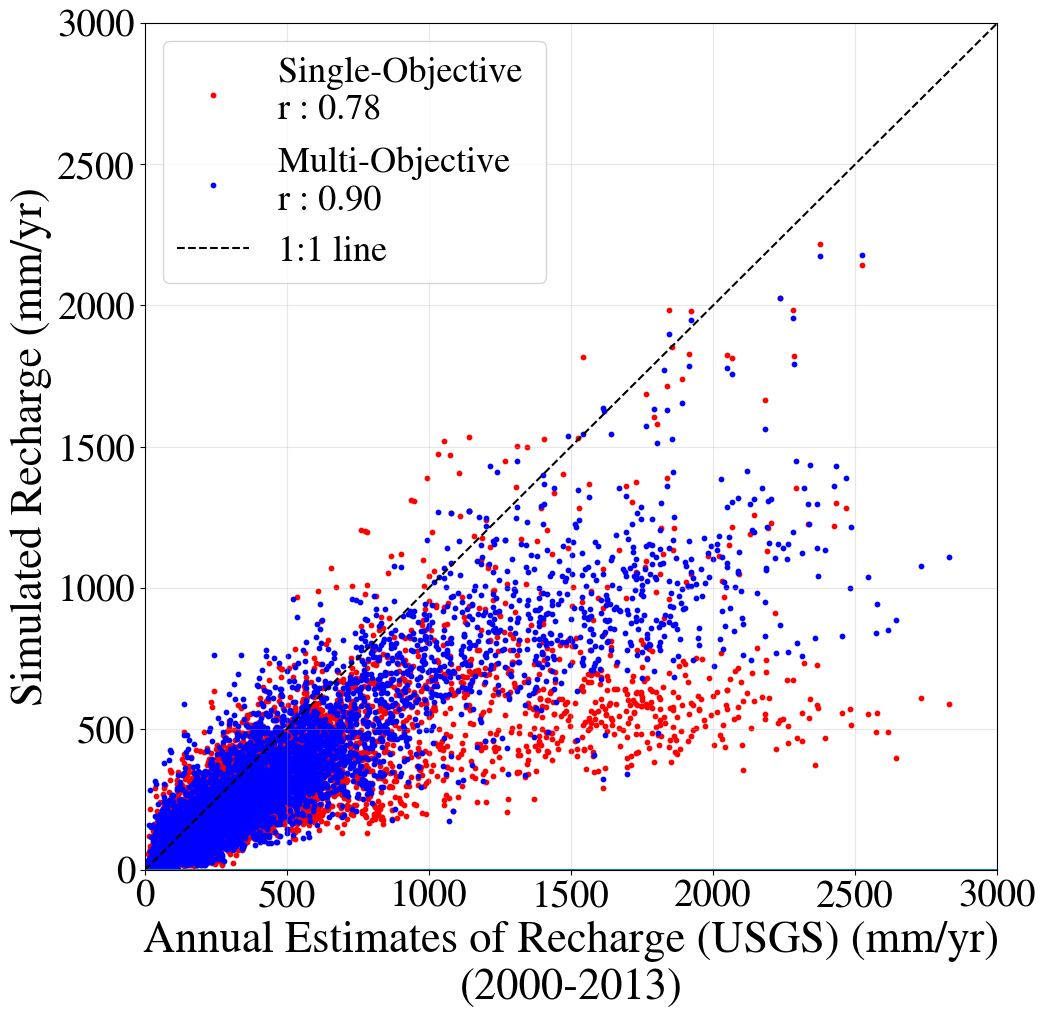

In [12]:
import matplotlib.pyplot as plt
 
plt.rcParams['font.family']= 'Nimbus Roman'
 
plt.figure(figsize=(11, 11))
plt.scatter(df['tiff'],df['sim_old'],color='red', s=10, label= f"Single-Objective \nr : {df['tiff'].corr(df['sim_old']):.2f}")
plt.scatter(df['tiff'],df['sim_new'],color='blue', s=10, label= f"Multi-Objective \nr : {df['tiff'].corr(df['sim_new']):.2f}")
 
plt.plot([0, 3000], [0, 3000], 'k--', label='1:1 line')
 
plt.xlabel('Annual Estimates of Recharge (USGS) (mm/yr)\n(2000-2013)',fontsize=32)
plt.ylabel('Simulated Recharge (mm/yr)',fontsize=32)
plt.axhline()
plt.xlim(0,3000)
plt.ylim(0,3000)
plt.xticks(fontsize=28)
plt.yticks(fontsize=28)
plt.legend(fontsize=26)
plt.grid(alpha=0.3)
plt.show()